# Trainability as Differential Information Transmission in Variational Quantum Circuits

[![Python](https://img.shields.io/badge/python-3.9%2B-blue)](https://www.python.org/)
[![Qiskit](https://img.shields.io/badge/Qiskit-1.2%2B-purple)](https://qiskit.org/)
[![License](https://img.shields.io/badge/license-MIT-green)](LICENSE)

**Authors:** F. Ailabouni & R. Casado

---

## Overview

This notebook reproduces all numerical experiments and figures from the paper:

> *Trainability as differential information transmission in variational quantum circuits*

The paper models trainability as the transmission of task-relevant differential information
through the Jacobian of a parametrized quantum circuit. Two independent mechanisms can
suppress this signal: **spectral suppression**, in which the Jacobian directions carry little
energy, and **alignment suppression**, in which those directions carry energy but point away
from the task gradient. The dynamical Lie algebra (DLA) sets an upper bound on what is
dynamically accessible, but circuits with the same DLA can realize markedly different Jacobian
geometries, and apparent gradient decay with system size can be explained by causal-cone
dilution rather than a true barren plateau.

**Reproducibility.** All experiments use a fixed global seed (`GLOBAL_SEED = 1234`) plus
experiment-specific seeds, exact noiseless statevector simulation (no shots/hardware noise),
and centered finite differences for gradients and the metric tensor. Expensive workloads are
parallelized across independent circuit instances with `joblib`, which does not change the
random sample or any numerical result.

### Key quantities

| Concept | Description |
|---|---|
| Modal (Jacobian-SVD) decomposition | Singular-value decomposition of the parameter-to-state Jacobian, giving the spectral weight and task alignment of each mode |
| Spectral weight $S_{\mathrm{spec}}$ | Total singular-value energy accessible to the parametrization |
| Normalized alignment $\mathcal A$ | Fraction of the task-gradient norm captured by the Jacobian's row space |
| Task-weighted transmission $\langle\sigma^2\rangle_{\mathrm{task}}$ | Joint spectral/alignment quantity that predicts the actual parameter gradient |

### Experiments

| Section | Question | Output |
|---|---|---|
| Validation 0 | Consistency check for the numerical engine (modal identity) | `fig_validation0_modal_identity.pdf` |
| Validation I | Spectral vs. alignment suppression are independent mechanisms | Figure 1 |
| Validation II | DLA-equivalent circuits can realize different Jacobian geometry | Figures 2–3 |
| Validation III | Scaling of spectral accessibility and alignment with system size | Figure 4 |
| Validation IV | Predictive power of Jacobian diagnostics for actual training outcomes | Figure 5, Table 1 |
| Validation V | Second-order smooth-map geometry and the exact Hessian transmission law | Figure 6 |
| Robustness controls | Balanced predictive cohorts, optimizer/hyperparameter sensitivity, paired significance tests, numerical-sensitivity checks | supplementary tables |

Figures are written to `figures_jacobian_qfim/` and the underlying dataframes to
`data_jacobian_qfim/` (see the export cell at the end of the notebook). Robustness-control
outputs are written to `robustness_controls/`.

---

## Repository structure

```
.
├── R1_trainability_jacobian_diagnostics.ipynb  # This notebook
├── figures_jacobian_qfim/    # Auto-generated figures (PDF + PNG)
├── data_jacobian_qfim/       # Auto-generated result tables (CSV)
└── robustness_controls/      # Auto-generated robustness-control tables (CSV)
```

## Requirements

```bash
pip install "qiskit>=1.2" "numpy>=2.0" "scipy>=1.14" pandas matplotlib "joblib>=1.3"
```


## Notebook ↔ paper correspondence

| Notebook section | Paper reference | Output |
|---|---|---|
| Validation 0 | consistency check for the numerical engine (modal identity, Eq. 12) | `fig_validation0_modal_identity.pdf` |
| Validation I | Section 5.2 — spectral vs. alignment suppression | Figure 1 |
| Validation II | Section 5.3 — DLA-equivalent circuits, Jacobian geometry | Figures 2–3 |
| Validation III | Section 5.4 — scaling of spectral accessibility and alignment | Figure 4 |
| Validation IV | Section 5.5 — predictive power of Jacobian diagnostics | Figure 5, Table 1 |
| Validation V | Section 5.6 — second-order smooth-map geometry and exact Hessian transmission law | Figure 6 |

Figures are written to `figures_jacobian_qfim/` and the underlying dataframes to `data_jacobian_qfim/` (see the export cell at the end of the notebook).


| Robustness controls | supplementary validation beyond the main-text figures | stratified predictive controls, optimizer/hyperparameter sensitivity, paired tests, numerical-sensitivity checks |


In [1]:
import os
for _var in ("OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
    os.environ[_var] = "1"

try:
    import qiskit
    import joblib
    print("Qiskit version:", qiskit.__version__)
    print("joblib version:", joblib.__version__)
except ImportError:
    %pip install -q "qiskit>=1.2" "numpy>=2.0" "scipy>=1.14" pandas matplotlib "joblib>=1.3"
    import qiskit
    import joblib
    print("Qiskit version:", qiskit.__version__)
    print("joblib version:", joblib.__version__)


Qiskit version: 2.5.2
joblib version: 1.5.1


In [2]:
import os
import math
import time
import itertools
from dataclasses import dataclass
from typing import Callable, Dict, List, Tuple, Optional, Sequence

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from joblib import Parallel, delayed, parallel_config
from qiskit import QuantumCircuit
from qiskit.quantum_info import SparsePauliOp

np.set_printoptions(precision=5, suppress=True)

FIG_DIR = "figures_jacobian_qfim"
os.makedirs(FIG_DIR, exist_ok=True)

GLOBAL_SEED = 1234
rng = np.random.default_rng(GLOBAL_SEED)

# ------------------------------------------------------------------
# Parallel execution
# ------------------------------------------------------------------
# These finite-difference workloads are CPU-bound and embarrassingly
# parallel across independent circuit instances, so we cap the worker
# pool at a conservative number of processes that leaves headroom for
# the OS. Adjust PARALLEL_N_JOBS to match the available hardware.
PARALLEL_ENABLED = True
PARALLEL_N_JOBS = min(12, os.cpu_count() or 1)
PARALLEL_BACKEND = "loky"

def _parallel_map(worker, tasks, n_jobs: Optional[int] = None, verbose: int = 0):
    """Process independent tasks with joblib/loky.

    Each worker is a separate process.  inner_max_num_threads=1 prevents
    NumPy/BLAS from starting nested thread pools inside every process.
    """
    tasks = list(tasks)
    if not tasks:
        return []

    nj = PARALLEL_N_JOBS if n_jobs is None else max(1, int(n_jobs))
    nj = min(nj, len(tasks))

    if (not PARALLEL_ENABLED) or nj <= 1:
        return [worker(task) for task in tasks]

    with parallel_config(backend=PARALLEL_BACKEND, inner_max_num_threads=1):
        return Parallel(
            n_jobs=nj,
            backend=PARALLEL_BACKEND,
            batch_size=1,
            verbose=verbose,
        )(delayed(worker)(task) for task in tasks)

def _task_batches(tasks, batch_size: int):
    """Yield deterministic batches so the parent process can checkpoint safely."""
    tasks = list(tasks)
    batch_size = max(1, int(batch_size))
    for start in range(0, len(tasks), batch_size):
        yield tasks[start:start + batch_size]

print(
    f"Parallel execution: {'ON' if PARALLEL_ENABLED else 'OFF'} | "
    f"workers={PARALLEL_N_JOBS} | logical CPUs detected={os.cpu_count()}"
)

# Metric convention
# -----------------
# The numerical engine uses pure-state tangent vectors.  For consistency with the
# Hilbert--Schmidt density-matrix Jacobian used in the paper,
# Tr(d rho_i d rho_j) = 2 g_FS, so we multiply the Fubini--Study metric by 2.
# Setting METRIC_SCALE = 1.0 recovers the raw Fubini--Study convention.
METRIC_SCALE = 2.0
METRIC_NAME = "Hilbert-Schmidt density-matrix metric = 2 × Fubini-Study"
print("Metric convention:", METRIC_NAME)


Parallel execution: ON | workers=12 | logical CPUs detected=20
Metric convention: Hilbert-Schmidt density-matrix metric = 2 × Fubini-Study


## Core statevector engine

The simulator below is intentionally lightweight. We use Qiskit to construct circuits for documentation/visual inspection, but all metrics are computed directly from statevectors. This makes finite differences and repeated sampling much faster and easier to control.

In [3]:
I2 = np.eye(2, dtype=complex)
X = np.array([[0, 1], [1, 0]], dtype=complex)
Y = np.array([[0, -1j], [1j, 0]], dtype=complex)
Z = np.array([[1, 0], [0, -1]], dtype=complex)
PAULI = {"I": I2, "X": X, "Y": Y, "Z": Z}


def RX(theta):
    return np.cos(theta/2)*I2 - 1j*np.sin(theta/2)*X


def RY(theta):
    return np.cos(theta/2)*I2 - 1j*np.sin(theta/2)*Y


def RZ(theta):
    return np.cos(theta/2)*I2 - 1j*np.sin(theta/2)*Z


def RXX(theta):
    XX = np.kron(X, X)
    return np.cos(theta/2)*np.eye(4, dtype=complex) - 1j*np.sin(theta/2)*XX


def RZZ(theta):
    ZZ = np.kron(Z, Z)
    return np.cos(theta/2)*np.eye(4, dtype=complex) - 1j*np.sin(theta/2)*ZZ


def zero_state(n: int) -> np.ndarray:
    psi = np.zeros(2**n, dtype=complex)
    psi[0] = 1.0
    return psi


def apply_one_qubit_gate(psi: np.ndarray, U: np.ndarray, q: int, n: int) -> np.ndarray:
    # Qubit indexing: q=0 is the leftmost/logical first qubit.
    tensor = psi.reshape([2]*n)
    axes = [q] + [i for i in range(n) if i != q]
    inv_axes = np.argsort(axes)
    tensor_perm = np.transpose(tensor, axes).reshape(2, -1)
    updated = U @ tensor_perm
    updated = updated.reshape([2] + [2]*(n-1))
    return np.transpose(updated, inv_axes).reshape(-1)


def apply_two_qubit_gate(psi: np.ndarray, U4: np.ndarray, q1: int, q2: int, n: int) -> np.ndarray:
    if q1 == q2:
        raise ValueError("q1 and q2 must be different")
    axes_front = [q1, q2]
    axes_rest = [i for i in range(n) if i not in axes_front]
    axes = axes_front + axes_rest
    inv_axes = np.argsort(axes)
    tensor = psi.reshape([2]*n)
    tensor_perm = np.transpose(tensor, axes).reshape(4, -1)
    updated = U4 @ tensor_perm
    updated = updated.reshape([2, 2] + [2]*(n-2))
    return np.transpose(updated, inv_axes).reshape(-1)


def apply_pauli_string(psi: np.ndarray, pauli_string: str) -> np.ndarray:
    n = len(pauli_string)
    out = psi
    for q, p in enumerate(pauli_string):
        if p != "I":
            out = apply_one_qubit_gate(out, PAULI[p], q, n)
    return out


def expectation_pauli(psi: np.ndarray, pauli_string: str) -> float:
    return float(np.real(np.vdot(psi, apply_pauli_string(psi, pauli_string))))


def expectation_sparse_pauli(psi: np.ndarray, op: SparsePauliOp) -> float:
    # Qiskit Pauli labels are strings such as 'ZI'. We keep the same left-to-right convention.
    val = 0.0 + 0.0j
    for label, coeff in zip(op.paulis.to_labels(), op.coeffs):
        val += coeff * np.vdot(psi, apply_pauli_string(psi, label))
    return float(np.real(val))

## Ansatz specification

Each ansatz is represented by a list of gates. A gate may be parameterized, with `param` giving the index in the parameter vector. This is convenient for finite differences, parameter-shift gradients, QFIM estimation and circuit drawing.

In [4]:
@dataclass
class GateSpec:
    name: str
    qubits: Tuple[int, ...]
    param: Optional[int] = None
    fixed_angle: Optional[float] = None

@dataclass
class AnsatzSpec:
    name: str
    n_qubits: int
    n_params: int
    gates: List[GateSpec]
    generator_labels: List[str]
    description: str = ""


def run_ansatz_state(ansatz: AnsatzSpec, theta: np.ndarray) -> np.ndarray:
    psi = zero_state(ansatz.n_qubits)
    for g in ansatz.gates:
        angle = g.fixed_angle if g.param is None else theta[g.param]
        if g.name == "rx":
            psi = apply_one_qubit_gate(psi, RX(angle), g.qubits[0], ansatz.n_qubits)
        elif g.name == "ry":
            psi = apply_one_qubit_gate(psi, RY(angle), g.qubits[0], ansatz.n_qubits)
        elif g.name == "rz":
            psi = apply_one_qubit_gate(psi, RZ(angle), g.qubits[0], ansatz.n_qubits)
        elif g.name == "rxx":
            psi = apply_two_qubit_gate(psi, RXX(angle), g.qubits[0], g.qubits[1], ansatz.n_qubits)
        elif g.name == "rzz":
            psi = apply_two_qubit_gate(psi, RZZ(angle), g.qubits[0], g.qubits[1], ansatz.n_qubits)
        else:
            raise ValueError(f"Unknown gate {g.name}")
    return psi / np.linalg.norm(psi)


def ansatz_to_qiskit(ansatz: AnsatzSpec, theta: Optional[np.ndarray] = None) -> QuantumCircuit:
    qc = QuantumCircuit(ansatz.n_qubits)
    for g in ansatz.gates:
        angle = g.fixed_angle if g.param is None else (float(theta[g.param]) if theta is not None else 0.0)
        if g.name == "rx":
            qc.rx(angle, g.qubits[0])
        elif g.name == "ry":
            qc.ry(angle, g.qubits[0])
        elif g.name == "rz":
            qc.rz(angle, g.qubits[0])
        elif g.name == "rxx":
            qc.rxx(angle, g.qubits[0], g.qubits[1])
        elif g.name == "rzz":
            qc.rzz(angle, g.qubits[0], g.qubits[1])
        else:
            raise ValueError(f"Unknown gate {g.name}")
    return qc


def random_theta(ansatz: AnsatzSpec, seed: Optional[int] = None, scale: float = 2*np.pi) -> np.ndarray:
    local_rng = np.random.default_rng(seed)
    return local_rng.uniform(-scale/2, scale/2, size=ansatz.n_params)

In [5]:
def single_qubit_A() -> AnsatzSpec:
    # U_A = RZ(phi) RX(theta), acting on |0>.
    gates = [GateSpec("rx", (0,), 0), GateSpec("rz", (0,), 1)]
    return AnsatzSpec("1q_A_RZ_after_RX", 1, 2, gates, ["X0", "Z0"], "U_A = RZ(phi) RX(theta)")


def single_qubit_B() -> AnsatzSpec:
    # U_B = RX(theta) RZ(phi), i.e. RZ acts first on |0> and is stabilizer-inactive.
    gates = [GateSpec("rz", (0,), 1), GateSpec("rx", (0,), 0)]
    return AnsatzSpec("1q_B_RX_after_RZ", 1, 2, gates, ["X0", "Z0"], "U_B = RX(theta) RZ(phi)")


def two_qubit_A() -> AnsatzSpec:
    gates = [GateSpec("rxx", (0, 1), 0), GateSpec("rz", (0,), 1)]
    return AnsatzSpec("2q_A_RZ_after_RXX", 2, 2, gates, ["X0X1", "Z0"], "U_A = RZ_0(phi) RXX_01(theta)")


def two_qubit_B() -> AnsatzSpec:
    gates = [GateSpec("rz", (0,), 1), GateSpec("rxx", (0, 1), 0)]
    return AnsatzSpec("2q_B_RXX_after_RZ", 2, 2, gates, ["X0X1", "Z0"], "U_B = RXX_01(theta) RZ_0(phi)")


def dla_equiv_chain_A(n: int, layers: int = 1) -> AnsatzSpec:
    # Entangling RXX chain first, then RZ rotations. RZ rotations act after leaving the stabilizer.
    gates = []
    p = 0
    for _ in range(layers):
        for q in range(n-1):
            gates.append(GateSpec("rxx", (q, q+1), p)); p += 1
        for q in range(n):
            gates.append(GateSpec("rz", (q,), p)); p += 1
    labels = [f"X{q}X{q+1}" for q in range(n-1)] + [f"Z{q}" for q in range(n)]
    return AnsatzSpec(f"chain_A_n{n}_L{layers}", n, p, gates, labels, "RXX chain followed by RZ block")


def dla_equiv_chain_B(n: int, layers: int = 1) -> AnsatzSpec:
    # Same generator multiset as A, but stabilizer rotations are placed before RXX chains in each layer.
    gates = []
    p = 0
    for _ in range(layers):
        for q in range(n):
            gates.append(GateSpec("rz", (q,), p)); p += 1
        for q in range(n-1):
            gates.append(GateSpec("rxx", (q, q+1), p)); p += 1
    labels = [f"X{q}X{q+1}" for q in range(n-1)] + [f"Z{q}" for q in range(n)]
    return AnsatzSpec(f"chain_B_n{n}_L{layers}", n, p, gates, labels, "RZ block followed by RXX chain")


def hea_ansatz(n: int, layers: int = 2, entangler: str = "rzz") -> AnsatzSpec:
    gates = []
    p = 0
    for ell in range(layers):
        for q in range(n):
            gates.append(GateSpec("ry", (q,), p)); p += 1
            gates.append(GateSpec("rz", (q,), p)); p += 1
        for q in range(n-1):
            gates.append(GateSpec(entangler, (q, q+1), p)); p += 1
    labels = ["RY", "RZ", entangler.upper()]
    return AnsatzSpec(f"HEA_n{n}_L{layers}_{entangler}", n, p, gates, labels, "Hardware-efficient ansatz")


def local_rxrz_ansatz(n: int, layers: int = 2) -> AnsatzSpec:
    gates = []
    p = 0
    for ell in range(layers):
        for q in range(n):
            gates.append(GateSpec("rx", (q,), p)); p += 1
            gates.append(GateSpec("rz", (q,), p)); p += 1
        for q in range(n-1):
            gates.append(GateSpec("rzz", (q, q+1), p)); p += 1
    labels = ["RX", "RZ", "ZZ"]
    return AnsatzSpec(f"Local_RXRZ_n{n}_L{layers}", n, p, gates, labels, "Local RX/RZ plus nearest-neighbour RZZ")


def random_permutation_same_generators(base: AnsatzSpec, seed: int, name_suffix: str = "perm") -> AnsatzSpec:
    local_rng = np.random.default_rng(seed)
    gates = list(base.gates)
    local_rng.shuffle(gates)
    # Re-index parameters after shuffling.
    new_gates = []
    for p, g in enumerate(gates):
        new_gates.append(GateSpec(g.name, g.qubits, p, g.fixed_angle))
    return AnsatzSpec(base.name + f"_{name_suffix}_{seed}", base.n_qubits, len(new_gates), new_gates, base.generator_labels, "Random permutation of the same gate multiset")

def single_qubit_tied_XZ() -> AnsatzSpec:
    """One-parameter curve with a full X/Z dynamical generator set.

    Both gates share the same scalar parameter.  The DLA generated by X and Z
    is su(2), whereas the local Jacobian has rank one.  This makes it a useful
    control example for genuine directional misalignment.
    """
    gates = [GateSpec("rx", (0,), 0), GateSpec("rz", (0,), 0)]
    return AnsatzSpec("1q_tied_RX_RZ", 1, 1, gates, ["X0", "Z0"], "U(theta)=RZ(theta) RX(theta)")


## Gradients, QFIM/metric tensor and modal diagnostics

In [6]:
def cost_value(ansatz: AnsatzSpec, theta: np.ndarray, observable: SparsePauliOp) -> float:
    psi = run_ansatz_state(ansatz, theta)
    return expectation_sparse_pauli(psi, observable)


def finite_difference_gradient(ansatz: AnsatzSpec, theta: np.ndarray, observable: SparsePauliOp, eps: float = 1e-6) -> np.ndarray:
    grad = np.zeros(ansatz.n_params, dtype=float)
    for k in range(ansatz.n_params):
        tp = theta.copy(); tm = theta.copy()
        tp[k] += eps; tm[k] -= eps
        grad[k] = (cost_value(ansatz, tp, observable) - cost_value(ansatz, tm, observable)) / (2*eps)
    return grad


def state_derivatives(ansatz: AnsatzSpec, theta: np.ndarray, eps: float = 1e-6) -> List[np.ndarray]:
    derivs = []
    for k in range(ansatz.n_params):
        tp = theta.copy(); tm = theta.copy()
        tp[k] += eps; tm[k] -= eps
        derivs.append((run_ansatz_state(ansatz, tp) - run_ansatz_state(ansatz, tm)) / (2*eps))
    return derivs


def fs_metric_tensor(ansatz: AnsatzSpec, theta: np.ndarray, eps: float = 1e-6) -> np.ndarray:
    psi = run_ansatz_state(ansatz, theta)
    derivs = state_derivatives(ansatz, theta, eps=eps)
    p = ansatz.n_params
    G = np.zeros((p, p), dtype=float)
    overlaps_with_state = np.array([np.vdot(d, psi) for d in derivs])
    for i in range(p):
        for j in range(p):
            val = np.vdot(derivs[i], derivs[j]) - overlaps_with_state[i] * np.conj(overlaps_with_state[j])
            G[i, j] = np.real(val)
    return METRIC_SCALE * 0.5 * (G + G.T)


# ------------------------------------------------------------------
# Task-gradient norm on the DLA reachable orbit
# ------------------------------------------------------------------
# For the HEA/local families used here the generator set is fully controllable,
# so the reachable pure-state orbit is the full projective Hilbert space and
# ||g_rho||^2_HS = 2 Var_rho(O).  The {RXX,RZ} chain families have a smaller
# DLA.  For them we generate the Pauli-string Lie closure (dimension n(2n-1))
# and project the cost differential onto its orbit tangent space.  This keeps
# G_task consistent with g_rho = grad_M C in the theory rather than replacing
# it by the ambient-state gradient.

_DLA_LABEL_CACHE: Dict[Tuple[str, int], List[str]] = {}


def _gate_pauli_label(g: GateSpec, n: int) -> Optional[str]:
    chars = ["I"] * n
    if g.name == "rx": chars[g.qubits[0]] = "X"
    elif g.name == "ry": chars[g.qubits[0]] = "Y"
    elif g.name == "rz": chars[g.qubits[0]] = "Z"
    elif g.name == "rxx":
        chars[g.qubits[0]] = "X"; chars[g.qubits[1]] = "X"
    elif g.name == "rzz":
        chars[g.qubits[0]] = "Z"; chars[g.qubits[1]] = "Z"
    else: return None
    return "".join(chars)


def _pauli_to_symplectic(label: str) -> Tuple[int, int]:
    x = z = 0
    n = len(label)
    for q, c in enumerate(label):
        bit = 1 << (n - 1 - q)
        if c in ("X", "Y"): x |= bit
        if c in ("Z", "Y"): z |= bit
    return x, z


def _symplectic_to_pauli(x: int, z: int, n: int) -> str:
    out = []
    for q in range(n):
        bit = 1 << (n - 1 - q)
        xb, zb = bool(x & bit), bool(z & bit)
        out.append("Y" if xb and zb else "X" if xb else "Z" if zb else "I")
    return "".join(out)


def _anticommutes(a: Tuple[int, int], b: Tuple[int, int]) -> bool:
    return (((a[0] & b[1]).bit_count() + (a[1] & b[0]).bit_count()) & 1) == 1


def pauli_lie_closure(labels: Sequence[str]) -> List[str]:
    if not labels: return []
    n = len(labels[0])
    closure = {_pauli_to_symplectic(x) for x in labels if set(x) != {"I"}}
    changed = True
    while changed:
        changed = False
        current = list(closure)
        additions = set()
        for i, a in enumerate(current):
            for b in current[i+1:]:
                if _anticommutes(a, b):
                    c = (a[0] ^ b[0], a[1] ^ b[1])
                    if c != (0, 0) and c not in closure:
                        additions.add(c)
        if additions:
            closure.update(additions); changed = True
    return [_symplectic_to_pauli(x, z, n) for x, z in sorted(closure)]


def _is_full_pure_state_orbit(ansatz: AnsatzSpec) -> bool:
    # These families contain arbitrary local rotations plus a connected
    # entangling graph and generate the full pure-state orbit in the experiments.
    return (ansatz.name.startswith("HEA_") or
            ansatz.name.startswith("Local_RXRZ_") or
            ansatz.name.startswith("1q_A_") or
            ansatz.name.startswith("1q_B_") or
            ansatz.name.startswith("1q_tied_"))


def _observable_action(psi: np.ndarray, observable: SparsePauliOp) -> np.ndarray:
    out = np.zeros_like(psi, dtype=complex)
    for label, coeff in zip(observable.paulis.to_labels(), observable.coeffs):
        out += coeff * apply_pauli_string(psi, label)
    return out


def task_gradient_norm2(ansatz: AnsatzSpec, theta: np.ndarray, observable: SparsePauliOp,
                        tangent_tol: float = 1e-10) -> float:
    """Return ||grad_M C||^2 in the Hilbert--Schmidt metric on the DLA orbit."""
    psi = run_ansatz_state(ansatz, theta)
    Opsi = _observable_action(psi, observable)
    c = float(np.real(np.vdot(psi, Opsi)))

    if _is_full_pure_state_orbit(ansatz):
        var = float(np.real(np.vdot(Opsi, Opsi)) - c*c)
        return max(0.0, 2.0 * var)

    key = ("chain", ansatz.n_qubits)
    if key not in _DLA_LABEL_CACHE:
        gen_labels = sorted({_gate_pauli_label(g, ansatz.n_qubits) for g in ansatz.gates if _gate_pauli_label(g, ansatz.n_qubits) is not None})
        _DLA_LABEL_CACHE[key] = pauli_lie_closure(gen_labels)
    labels = _DLA_LABEL_CACHE[key]

    # Horizontal state tangents delta psi_P = -i(P-<P>)|psi>.
    D = []
    for label in labels:
        Ppsi = apply_pauli_string(psi, label)
        meanP = np.vdot(psi, Ppsi)
        D.append(-1j * (Ppsi - meanP * psi))
    D = np.column_stack(D)
    gram = 2.0 * np.real(D.conj().T @ D)  # Hilbert--Schmidt metric
    b = 2.0 * np.real(D.conj().T @ Opsi)  # dC(delta rho_P)

    w, Q = np.linalg.eigh(0.5 * (gram + gram.T))
    keep = w > tangent_tol
    if not np.any(keep): return 0.0
    coeff = Q[:, keep].T @ b
    return float(np.sum((coeff**2) / w[keep]))


def modal_diagnostics(ansatz: AnsatzSpec, theta: np.ndarray, observable: SparsePauliOp,
                      eps: float = 1e-6, rank_tol: float = 1e-10) -> Dict:
    grad = finite_difference_gradient(ansatz, theta, observable, eps=eps)
    G = fs_metric_tensor(ansatz, theta, eps=eps)
    evals, evecs = np.linalg.eigh(G)
    idx = np.argsort(evals)[::-1]
    evals = np.maximum(evals[idx], 0.0)
    evecs = evecs[:, idx]
    vgrad = evecs.T @ grad
    task_coeff = np.zeros_like(evals)
    mask = evals > rank_tol
    task_coeff[mask] = (vgrad[mask]**2) / evals[mask]
    modal_contrib = evals * task_coeff
    grad_norm2 = float(np.dot(grad, grad))
    recon_norm2 = float(np.sum(modal_contrib))

    align_sum = float(np.sum(task_coeff))
    gtask_norm2 = task_gradient_norm2(ansatz, theta, observable)
    normalized_alignment = align_sum / gtask_norm2 if gtask_norm2 > 1e-14 else np.nan
    # Numerical roundoff can produce values infinitesimally above one.
    if np.isfinite(normalized_alignment) and normalized_alignment <= 1.0 + 1e-7:
        normalized_alignment = min(1.0, max(0.0, normalized_alignment))

    spec_sum = float(np.sum(evals))
    spec_per_param = spec_sum / max(ansatz.n_params, 1)
    task_weighted_sigma2 = grad_norm2 / align_sum if align_sum > 1e-14 else np.nan

    # Basis-invariant mode blocks for degenerate singular values.  Individual
    # A_a values inside a degenerate block depend on the eigenbasis returned by
    # eigh, whereas their block sum does not.
    block_sigma2, block_task_coeff, block_contrib, block_mult = [], [], [], []
    active_indices = np.where(mask)[0]
    start = 0
    while start < len(active_indices):
        i0 = active_indices[start]; lam = evals[i0]; group = [i0]; j = start + 1
        while j < len(active_indices) and np.isclose(evals[active_indices[j]], lam, rtol=1e-8, atol=rank_tol):
            group.append(active_indices[j]); j += 1
        block_sigma2.append(float(np.mean(evals[group])))
        block_task_coeff.append(float(np.sum(task_coeff[group])))
        block_contrib.append(float(np.sum(modal_contrib[group])))
        block_mult.append(len(group)); start = j

    active_tol = max(1e-14, 1e-8 * max(grad_norm2, 1e-15))
    active_mask = (modal_contrib > active_tol) & mask
    active_sigma2 = evals[active_mask]
    if active_sigma2.size > 0:
        active_sigma2_min = float(np.min(active_sigma2))
        active_sigma2_max = float(np.max(active_sigma2))
        active_sigma2_ratio = float(active_sigma2_max / max(active_sigma2_min, 1e-300))
        active_sigma2_logspread = float(np.log10(active_sigma2_ratio))
    else:
        active_sigma2_min = active_sigma2_max = 0.0
        active_sigma2_ratio = active_sigma2_logspread = np.nan

    return {
        "grad": grad, "G": G, "sigma2": evals, "sigma": np.sqrt(evals), "V": evecs,
        "vgrad": vgrad, "align": task_coeff, "task_coeff": task_coeff,
        "modal_contrib": modal_contrib, "grad_norm2": grad_norm2,
        "recon_norm2": recon_norm2,
        "rel_error": abs(grad_norm2 - recon_norm2) / max(1e-15, grad_norm2),
        "rank_eps": int(np.sum(mask)), "spec_sum": spec_sum,
        "spec_per_param": spec_per_param, "align_sum": align_sum,
        "task_grad_norm2": gtask_norm2, "normalized_alignment": normalized_alignment,
        "task_weighted_sigma2": task_weighted_sigma2,
        "sigma_max": float(np.sqrt(evals[0])) if len(evals) else 0.0,
        "sigma_min_pos": float(np.sqrt(evals[mask][-1])) if np.any(mask) else 0.0,
        "active_n": int(np.sum(active_mask)), "active_sigma2_min": active_sigma2_min,
        "active_sigma2_max": active_sigma2_max, "active_sigma2_ratio": active_sigma2_ratio,
        "active_sigma2_logspread": active_sigma2_logspread,
        # Retain the full mode-resolved data for basis-invariant, mode-resolved analyses.
        "sigma2_active": evals[mask].copy(), "task_coeff_active": task_coeff[mask].copy(),
        "modal_contrib_active": modal_contrib[mask].copy(),
        "block_sigma2": block_sigma2, "block_task_coeff": block_task_coeff,
        "block_modal_contrib": block_contrib, "block_multiplicity": block_mult,
    }


def make_observable(label: str, coeff: float = 1.0) -> SparsePauliOp:
    return SparsePauliOp.from_list([(label, coeff)])


def local_Z(n: int, q: int = 0) -> SparsePauliOp:
    label = ["I"]*n; label[q] = "Z"; return make_observable("".join(label))

def local_X(n: int, q: int = 0) -> SparsePauliOp:
    label = ["I"]*n; label[q] = "X"; return make_observable("".join(label))

def global_Z(n: int) -> SparsePauliOp: return make_observable("Z"*n)


def global_mixed_phase_string(n: int) -> SparsePauliOp:
    if n == 1: return make_observable("X")
    label = ["X"] * n; label[0] = "Y"; return make_observable("".join(label))


def nearest_neighbor_yx_observable(n: int, normalize: bool = True) -> SparsePauliOp:
    if n < 2: return local_X(n, 0)
    coeff = 1.0 / (n - 1) if normalize else 1.0
    terms = []
    for q in range(n - 1):
        label = ["I"] * n; label[q] = "Y"; label[q + 1] = "X"
        terms.append(("".join(label), coeff))
    return SparsePauliOp.from_list(terms)


def nearest_neighbor_xy_yx_observable(n: int, normalize: bool = True) -> SparsePauliOp:
    if n < 2: return local_X(n, 0)
    coeff = 1.0 / (2 * (n - 1)) if normalize else 1.0
    terms = []
    for q in range(n - 1):
        for a, b in [("Y", "X"), ("X", "Y")]:
            label = ["I"] * n; label[q] = a; label[q + 1] = b
            terms.append(("".join(label), coeff))
    return SparsePauliOp.from_list(terms)


def random_pauli_observable(n: int, seed: int, n_terms: int = 4) -> SparsePauliOp:
    local_rng = np.random.default_rng(seed)
    terms = []
    for _ in range(n_terms):
        label = "".join(local_rng.choice(list("IXYZ"), size=n))
        if set(label) == {"I"}: label = "Z" + "I"*(n-1)
        terms.append((label, local_rng.normal()))
    return SparsePauliOp.from_list(terms)


# Validation 0 — computational engine and modal identity

In [7]:
def validation_0_modal_identity(n_samples: int = 50, max_n: int = 6, seed: int = 10, eps: float = 1e-6) -> pd.DataFrame:
    local_rng = np.random.default_rng(seed)
    rows = []
    for s in range(n_samples):
        n = int(local_rng.integers(1, max_n+1))
        L = int(local_rng.integers(1, 3))
        family = local_rng.choice(["hea", "local", "chainA", "chainB"])
        if family == "hea":
            ans = hea_ansatz(n, L, entangler="rzz")
        elif family == "local":
            ans = local_rxrz_ansatz(n, L)
        elif family == "chainA":
            ans = dla_equiv_chain_A(n, L)
        else:
            ans = dla_equiv_chain_B(n, L)
        obs = random_pauli_observable(n, seed=1000+s, n_terms=3)
        theta = local_rng.uniform(-np.pi, np.pi, size=ans.n_params)
        diag = modal_diagnostics(ans, theta, obs, eps=eps)
        rows.append({
            "sample": s,
            "n": n,
            "L": L,
            "family": family,
            "p": ans.n_params,
            "grad_norm2": diag["grad_norm2"],
            "recon_norm2": diag["recon_norm2"],
            "rel_error": diag["rel_error"],
            "rank_eps": diag["rank_eps"],
            "sigma_max": diag["sigma_max"],
            "spec_sum": diag["spec_sum"],
            "align_sum": diag["align_sum"],
        })
    return pd.DataFrame(rows)

val0_df = validation_0_modal_identity(n_samples=40, max_n=5, seed=7)
val0_df.head(), val0_df["rel_error"].describe()

(   sample  n  L  family   p    grad_norm2  recon_norm2     rel_error  \
 0       0  5  2  chainA  18  3.407908e+00     3.407908  5.212455e-16   
 1       1  5  1     hea  14  8.998327e-02     0.089983  3.084526e-16   
 2       2  5  1  chainA   9  7.352506e-01     0.735251  3.019985e-16   
 3       3  2  1     hea   5  9.938109e-01     0.993811  2.234274e-16   
 4       4  1  1  chainA   1  1.109336e-19     0.000000  1.109336e-04   
 
    rank_eps  sigma_max  spec_sum  align_sum  
 0        18   1.050246  8.029130   6.545991  
 1        14   0.840570  3.688510   0.203882  
 2         9   0.880823  3.839069   1.470501  
 3         5   0.723017  1.571257   2.243774  
 4         0   0.000000  0.000000   0.000000  ,
 count    4.000000e+01
 mean     2.793887e-06
 std      1.753708e-05
 min      0.000000e+00
 25%      1.288703e-16
 50%      2.811611e-16
 75%      4.933650e-16
 max      1.109336e-04
 Name: rel_error, dtype: float64)

'figures_jacobian_qfim\\fig_validation0_modal_identity.pdf'

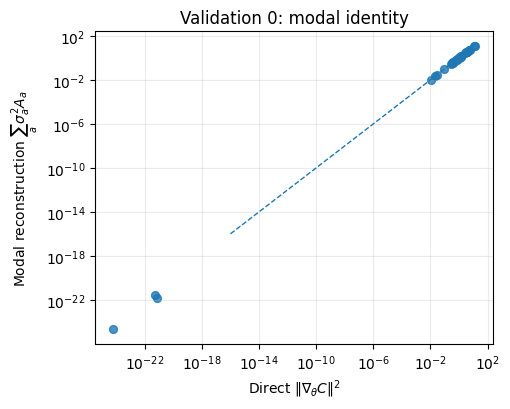

In [8]:
def plot_validation_0(df: pd.DataFrame, filename: str = "fig_validation0_modal_identity.pdf"):
    fig, ax = plt.subplots(figsize=(5.2, 4.2))
    x = df["grad_norm2"].to_numpy()
    y = df["recon_norm2"].to_numpy()
    ax.scatter(x, y, s=32, alpha=0.8)
    lo = max(min(x.min(), y.min()), 1e-16)
    hi = max(x.max(), y.max())
    ax.plot([lo, hi], [lo, hi], linestyle="--", linewidth=1)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(r"Direct $\|\nabla_\theta C\|^2$")
    ax.set_ylabel(r"Modal reconstruction $\sum_a \sigma_a^2 A_a$")
    ax.set_title("Validation 0: modal identity")
    ax.grid(True, which="both", alpha=0.25)
    fig.tight_layout()
    path = os.path.join(FIG_DIR, filename)
    fig.savefig(path, bbox_inches="tight")
    return path

plot_validation_0(val0_df)

# Validation I — independent spectral and alignment suppression

In [9]:
def validation_I_one_qubit_grid(num: int = 200, eps: float = 1e-6) -> pd.DataFrame:
    rows = []
    # Spectral suppression: original two-parameter example.  The task-gradient
    # magnitude remains finite while one Jacobian singular mode collapses.
    ans_spec = single_qubit_A(); obs_X = make_observable("X")
    for theta_val in np.linspace(1e-3, np.pi-1e-3, num):
        theta = np.array([theta_val, 0.0])
        d = modal_diagnostics(ans_spec, theta, obs_X, eps=eps)
        rows.append({"mechanism":"spectral_X_phi0", "theta":theta_val,
                     "sigma2_mode2":d["sigma2"][1], "task_coeff_mode2":d["task_coeff"][1],
                     "contrib_mode2":d["modal_contrib"][1], "grad_norm2":d["grad_norm2"],
                     "task_grad_norm2":d["task_grad_norm2"], "normalized_alignment":d["normalized_alignment"]})

    # Genuine directional-alignment suppression.  RX(theta) and RZ(theta) share
    # one parameter: the DLA is su(2) but Im(J) is one-dimensional.  With O=Y,
    # G_task stays bounded away from zero while the normalized projector overlap
    # A varies strongly.  The singular value stays O(1), excluding spectral collapse.
    ans_align = single_qubit_tied_XZ(); obs_Y = make_observable("Y")
    for theta_val in np.linspace(1e-3, np.pi-1e-3, num):
        theta = np.array([theta_val])
        d = modal_diagnostics(ans_align, theta, obs_Y, eps=eps)
        rows.append({"mechanism":"alignment_tied_XZ_Y", "theta":theta_val,
                     "sigma2_mode2":d["sigma2"][0], "task_coeff_mode2":d["task_coeff"][0],
                     "contrib_mode2":d["modal_contrib"][0], "grad_norm2":d["grad_norm2"],
                     "task_grad_norm2":d["task_grad_norm2"], "normalized_alignment":d["normalized_alignment"]})
    return pd.DataFrame(rows)

valI_df = validation_I_one_qubit_grid()
valI_df.head()


,mechanism,theta,sigma2_mode2,task_coeff_mode2,contrib_mode2,grad_norm2,task_grad_norm2,normalized_alignment
0,spectral_X_phi0,0.001000,4.999998e-07,2.0,9.999997e-07,9.999997e-07,2.0,1.0
1,spectral_X_phi0,0.016777,1.407181e-04,2.0,2.814362e-04,2.814362e-04,2.0,1.0
2,spectral_X_phi0,0.032554,5.296844e-04,2.0,1.059369e-03,1.059369e-03,2.0,1.0
3,spectral_X_phi0,0.048331,1.167012e-03,2.0,2.334023e-03,2.334023e-03,2.0,1.0
4,spectral_X_phi0,0.064107,2.052065e-03,2.0,4.104131e-03,4.104131e-03,2.0,1.0


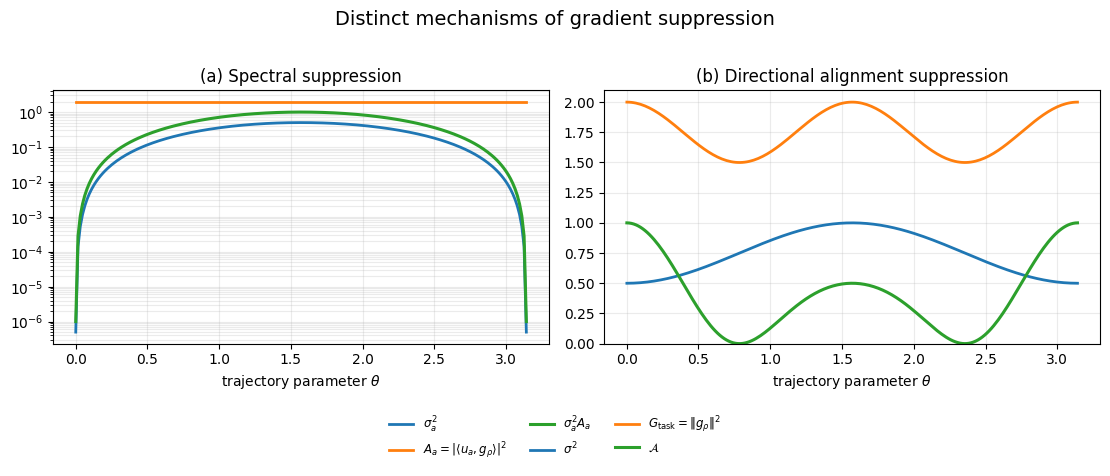

'figures_jacobian_qfim\\fig_validationI_suppression_mechanisms.pdf'

In [10]:
def plot_validation_I(df: pd.DataFrame, filename: str = "fig_validationI_suppression_mechanisms.pdf"):
    fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.4))
    spectral = df[df["mechanism"] == "spectral_X_phi0"]
    alignment = df[df["mechanism"] == "alignment_tied_XZ_Y"]

    ax = axes[0]
    ax.plot(spectral["theta"], spectral["sigma2_mode2"], linewidth=2.0, label=r"$\sigma_a^2$")
    ax.plot(spectral["theta"], spectral["task_coeff_mode2"], linewidth=2.0, label=r"$A_a=|\langle u_a,g_\rho\rangle|^2$")
    ax.plot(spectral["theta"], spectral["contrib_mode2"], linewidth=2.2, label=r"$\sigma_a^2A_a$")
    ax.set_yscale("log"); ax.set_xlabel(r"trajectory parameter $\theta$")
    ax.set_title("(a) Spectral suppression"); ax.grid(True, which="both", alpha=0.25)

    ax = axes[1]
    ax.plot(alignment["theta"], alignment["sigma2_mode2"], linewidth=2.0, label=r"$\sigma^2$")
    ax.plot(alignment["theta"], alignment["task_grad_norm2"], linewidth=2.0, label=r"$G_{\rm task}=\|g_\rho\|^2$")
    ax.plot(alignment["theta"], alignment["normalized_alignment"], linewidth=2.2, label=r"$\mathcal{A}$")
    ax.set_xlabel(r"trajectory parameter $\theta$"); ax.set_ylim(bottom=0)
    ax.set_title("(b) Directional alignment suppression"); ax.grid(True, alpha=0.25)

    handles, labels = [], []
    for a in axes:
        h,l=a.get_legend_handles_labels(); handles.extend(h); labels.extend(l)
    # de-duplicate labels
    unique=dict(zip(labels,handles))
    fig.legend(unique.values(), unique.keys(), loc="lower center", bbox_to_anchor=(0.5,-0.03), ncol=3, frameon=False, fontsize=8.5)
    fig.suptitle("Distinct mechanisms of gradient suppression", y=1.02, fontsize=14)
    fig.tight_layout(rect=[0,0.12,1,1])
    path=os.path.join(FIG_DIR,filename); fig.savefig(path,bbox_inches="tight"); fig.savefig(path.replace('.pdf','.png'),dpi=300,bbox_inches="tight")
    plt.show(); return path

plot_validation_I(valI_df)


# Validation II — same DLA, different Jacobian geometry

In [11]:
def compare_pair(ansA: AnsatzSpec, ansB: AnsatzSpec, thetaA: np.ndarray, thetaB: np.ndarray, obs: SparsePauliOp, eps: float = 1e-6) -> Dict:
    dA = modal_diagnostics(ansA, thetaA, obs, eps=eps)
    dB = modal_diagnostics(ansB, thetaB, obs, eps=eps)
    return {
        "name_A": ansA.name,
        "name_B": ansB.name,
        "same_generator_labels": set(ansA.generator_labels) == set(ansB.generator_labels),
        "rank_A": dA["rank_eps"],
        "rank_B": dB["rank_eps"],
        "sigma_max_A": dA["sigma_max"],
        "sigma_max_B": dB["sigma_max"],
        "spec_sum_A": dA["spec_sum"],
        "spec_sum_B": dB["spec_sum"],
        "grad_norm2_A": dA["grad_norm2"],
        "grad_norm2_B": dB["grad_norm2"],
    }

# One- and two-qubit direct checks
ans1A, ans1B = single_qubit_A(), single_qubit_B()
ans2A, ans2B = two_qubit_A(), two_qubit_B()

pair_rows = []
pair_rows.append(compare_pair(ans1A, ans1B, np.array([0.8, 1.1]), np.array([0.8, 1.1]), make_observable("X")))
pair_rows.append(compare_pair(ans2A, ans2B, np.array([0.8, 1.1]), np.array([0.8, 1.1]), make_observable("XI")))
pd.DataFrame(pair_rows)

,name_A,name_B,same_generator_labels,rank_A,rank_B,sigma_max_A,sigma_max_B,spec_sum_A,spec_sum_B,grad_norm2_A,grad_norm2_B
0,1q_A_RZ_after_RX,1q_B_RX_after_RZ,True,2,1,0.707107,0.707107,0.7573,0.5,0.491408,7.703720e-22
1,2q_A_RZ_after_RXX,2q_B_RXX_after_RZ,True,2,1,0.707107,0.707107,0.7573,0.5,0.000000,0.000000e+00


In [12]:
def _validation_II_scaling_worker(task) -> List[Dict]:
    n, layers, sample, theta_shared, eps, observable_builder, observable_name = task
    obs = observable_builder(n)
    builders = [
        ("A_entangle_then_RZ", dla_equiv_chain_A),
        ("B_RZ_then_entangle", dla_equiv_chain_B),
    ]
    rows = []
    p_ref = builders[0][1](n, layers).n_params

    for family_name, builder in builders:
        ans = builder(n, layers)
        if ans.n_params != p_ref:
            raise RuntimeError("A/B parameter counts unexpectedly differ; paired construction is invalid.")
        diag = modal_diagnostics(ans, np.asarray(theta_shared, float), obs, eps=eps)
        rows.append({
            "n": n,
            "layers": layers,
            "family": family_name,
            "sample": sample,
            "observable": observable_name,
            "p": ans.n_params,
            "same_generator_set": True,
            "rank_eps": diag["rank_eps"],
            "sigma_max": diag["sigma_max"],
            "spec_sum": diag["spec_sum"],
            "spec_per_param": diag["spec_per_param"],
            "align_sum": diag["align_sum"],
            "task_grad_norm2": diag["task_grad_norm2"],
            "normalized_alignment": diag["normalized_alignment"],
            "task_weighted_sigma2": diag["task_weighted_sigma2"],
            "grad_norm2": diag["grad_norm2"],
            "recon_norm2": diag["recon_norm2"],
            "rel_error": diag["rel_error"],
        })
    return rows


def validation_II_scaling(
    ns=(2,3,4,5,6,7,8,10),
    layers: int = 1,
    n_samples: int = 150,
    seed: int = 20,
    eps: float = 1e-6,
    observable_builder: Callable[[int], SparsePauliOp] = nearest_neighbor_yx_observable,
    observable_name: str = "nearest_neighbor_YX",
    n_jobs: Optional[int] = None,
) -> pd.DataFrame:
    """Scaling test for DLA-equivalent A/B chain families.

    The same random parameter vector is used for A and B at each (n, sample),
    so the comparison is paired.  Tasks are generated deterministically in the
    parent process and then distributed across independent worker processes.
    """
    local_rng = np.random.default_rng(seed)
    tasks = []

    for n in ns:
        p_ref = dla_equiv_chain_A(n, layers).n_params
        for s in range(n_samples):
            theta_shared = local_rng.uniform(-np.pi, np.pi, size=p_ref)
            tasks.append(
                (int(n), int(layers), int(s), theta_shared, float(eps),
                 observable_builder, observable_name)
            )

    nested = _parallel_map(_validation_II_scaling_worker, tasks, n_jobs=n_jobs)
    rows = [rec for pair in nested for rec in pair]
    return pd.DataFrame(rows).sort_values(["n", "sample", "family"]).reset_index(drop=True)


# Main paper-style dataset for Validation II.
# Parallelized across paired (n, sample) instances.
valII_df = validation_II_scaling(
    ns=(2,3,4,5,6,7,8),
    layers=1,
    n_samples=150,
    n_jobs=PARALLEL_N_JOBS,
)
valII_df.groupby(["n", "family"])[["rank_eps", "spec_sum", "grad_norm2", "align_sum"]].mean().head(12)


rank_eps  spec_sum  grad_norm2  align_sum
n family                                                       
2 A_entangle_then_RZ       2.0  1.031316    0.807053   1.507170
  B_RZ_then_entangle       1.0  0.500000    0.498100   0.996199
3 A_entangle_then_RZ       5.0  1.878803    0.285988   0.732759
  B_RZ_then_entangle       2.0  1.000000    0.256136   0.512271
4 A_entangle_then_RZ       7.0  2.706701    0.188655   0.442678
  B_RZ_then_entangle       3.0  1.500000    0.162557   0.325114
5 A_entangle_then_RZ       9.0  3.656064    0.143159   0.318368
  B_RZ_then_entangle       4.0  2.000000    0.124884   0.249768
6 A_entangle_then_RZ      11.0  4.529577    0.116048   0.255390
  B_RZ_then_entangle       5.0  2.500000    0.099912   0.199824
7 A_entangle_then_RZ      13.0  5.370498    0.093037   0.209146
  B_RZ_then_entangle       6.0  3.000000    0.086898   0.173796

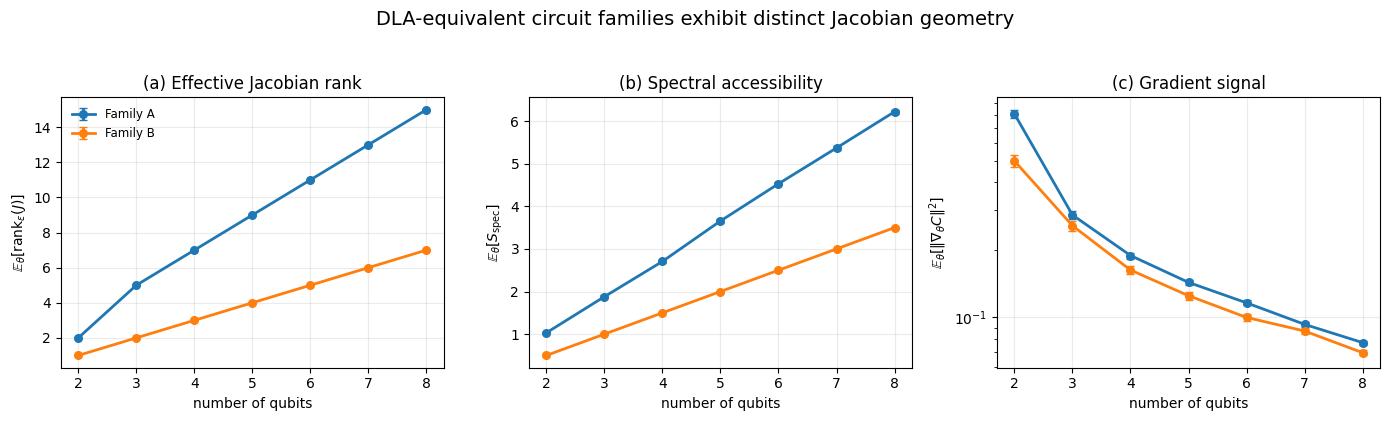

'figures_jacobian_qfim\\fig_validationII_dla_same_jacobian_different.pdf'

In [13]:
def plot_validation_II_scaling(
    df: pd.DataFrame,
    filename: str = "fig_validationII_dla_same_jacobian_different.pdf",
    use_sem: bool = True,
):
    grouped = df.groupby(["n", "family"])

    agg = grouped.agg(
        rank_mean=("rank_eps", "mean"),
        rank_std=("rank_eps", "std"),
        spec_mean=("spec_sum", "mean"),
        spec_std=("spec_sum", "std"),
        grad_mean=("grad_norm2", "mean"),
        grad_std=("grad_norm2", "std"),
        n_samples=("sample", "count"),
    ).reset_index()

    if use_sem:
        for prefix in ["rank", "spec", "grad"]:
            agg[f"{prefix}_err"] = (
                agg[f"{prefix}_std"].fillna(0)
                / np.sqrt(agg["n_samples"].clip(lower=1))
            )
    else:
        for prefix in ["rank", "spec", "grad"]:
            agg[f"{prefix}_err"] = agg[f"{prefix}_std"].fillna(0)

    family_labels = {
        "A_entangle_then_RZ": "Family A",
        "B_RZ_then_entangle": "Family B",
    }

    fig, axes = plt.subplots(1, 3, figsize=(14.0, 4.0))

    metrics = [
        (
            "rank_mean",
            "rank_err",
            r"$\mathbb{E}_\theta[\mathrm{rank}_\epsilon(J)]$",
            "(a) Effective Jacobian rank",
        ),
        (
            "spec_mean",
            "spec_err",
            r"$\mathbb{E}_\theta[S_{\mathrm{spec}}]$",
            "(b) Spectral accessibility",
        ),
        (
            "grad_mean",
            "grad_err",
            r"$\mathbb{E}_\theta[\|\nabla_\theta C\|^2]$",
            "(c) Gradient signal",
        ),
    ]

    for ax, (m, err, ylabel, title) in zip(axes, metrics):
        for fam in sorted(agg["family"].unique()):
            sub = agg[agg["family"] == fam].sort_values("n")

            ax.errorbar(
                sub["n"],
                sub[m],
                yerr=sub[err],
                marker="o",
                capsize=3,
                linewidth=2.0,
                markersize=5.5,
                label=family_labels.get(fam, fam),
            )

        ax.set_xlabel("number of qubits")
        ax.set_ylabel(ylabel)
        ax.set_title(title)
        ax.grid(True, alpha=0.25)

    if np.all(agg["grad_mean"].values > 0):
        axes[2].set_yscale("log")

    axes[0].legend(
        frameon=False,
        fontsize=8.5,
        loc="upper left",
    )

    fig.suptitle(
        "DLA-equivalent circuit families exhibit distinct Jacobian geometry",
        fontsize=14,
        y=1.04,
    )

    fig.tight_layout()

    path = os.path.join(FIG_DIR, filename)

    fig.savefig(
        path,
        bbox_inches="tight",
    )

    fig.savefig(
        path.replace(".pdf", ".png"),
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()

    return path


plot_validation_II_scaling(valII_df)

In [14]:
def _validation_II_permutation_worker(task) -> Dict:
    n, layers, s, seed, eps, observable_builder, observable_name = task
    base = dla_equiv_chain_A(n, layers)
    obs = observable_builder(n)
    ans = random_permutation_same_generators(base, seed=seed + s)
    theta = np.random.default_rng(seed + 1000 + s).uniform(
        -np.pi, np.pi, size=ans.n_params
    )
    diag = modal_diagnostics(ans, theta, obs, eps=eps)
    return {
        "perm": s,
        "n": n,
        "layers": layers,
        "observable": observable_name,
        "rank_eps": diag["rank_eps"],
        "sigma_max": diag["sigma_max"],
        "spec_sum": diag["spec_sum"],
        "spec_per_param": diag["spec_per_param"],
        "align_sum": diag["align_sum"],
        "task_grad_norm2": diag["task_grad_norm2"],
        "normalized_alignment": diag["normalized_alignment"],
        "task_weighted_sigma2": diag["task_weighted_sigma2"],
        "block_sigma2": diag["block_sigma2"],
        "block_task_coeff": diag["block_task_coeff"],
        "block_modal_contrib": diag["block_modal_contrib"],
        "block_multiplicity": diag["block_multiplicity"],
        "grad_norm2": diag["grad_norm2"],
    }


def validation_II_permutation_distribution(
    n: int = 6,
    layers: int = 2,
    n_perms: int = 200,
    seed: int = 30,
    eps: float = 1e-6,
    observable_builder: Callable[[int], SparsePauliOp] = nearest_neighbor_yx_observable,
    observable_name: str = "nearest_neighbor_YX",
    n_jobs: Optional[int] = None,
) -> pd.DataFrame:
    tasks = [
        (int(n), int(layers), int(s), int(seed), float(eps),
         observable_builder, observable_name)
        for s in range(n_perms)
    ]
    rows = _parallel_map(_validation_II_permutation_worker, tasks, n_jobs=n_jobs)
    return pd.DataFrame(rows).sort_values("perm").reset_index(drop=True)


perm_df = validation_II_permutation_distribution(
    n=6, layers=2, n_perms=200, n_jobs=PARALLEL_N_JOBS
)
perm_df.describe()


,perm,n,layers,rank_eps,sigma_max,spec_sum,spec_per_param,align_sum,task_grad_norm2,normalized_alignment,task_weighted_sigma2,grad_norm2
count,200.000000,200.0,200.0,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000
mean,99.500000,6.0,2.0,12.530000,1.133319,7.562822,0.343765,0.246093,0.326859,0.746078,0.692269,0.169990
std,57.879185,0.0,0.0,2.024746,0.106238,0.881371,0.040062,0.064464,0.052533,0.117537,0.170598,0.060035
min,0.000000,6.0,2.0,8.000000,1.000000,5.439745,0.247261,0.096467,0.167098,0.464322,0.254938,0.046295
25%,49.750000,6.0,2.0,11.000000,1.045311,6.896227,0.313465,0.191625,0.290888,0.666277,0.580518,0.129441
50%,99.500000,6.0,2.0,13.000000,1.123544,7.612473,0.346021,0.247347,0.329736,0.763552,0.684543,0.163130
75%,149.250000,6.0,2.0,14.000000,1.196799,8.140961,0.370044,0.298170,0.369222,0.833995,0.787945,0.206027
max,199.000000,6.0,2.0,19.000000,1.410266,10.677203,0.485327,0.401735,0.464820,0.969586,1.379019,0.371968


'figures_jacobian_qfim\\fig_validationII_permutation_distribution.pdf'

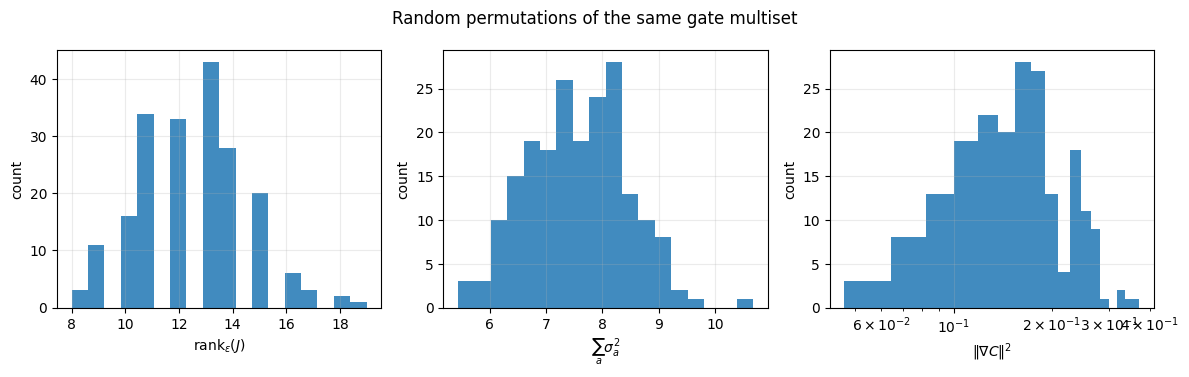

In [15]:
def plot_permutation_distribution(df: pd.DataFrame, filename: str = "fig_validationII_permutation_distribution.pdf"):
    fig, axes = plt.subplots(1, 3, figsize=(12.0, 3.8))
    for ax, col, xlabel in zip(
        axes,
        ["rank_eps", "spec_sum", "grad_norm2"],
        [r"$\mathrm{rank}_\epsilon(J)$", r"$\sum_a\sigma_a^2$", r"$\|\nabla C\|^2$"]
    ):
        ax.hist(df[col], bins=18, alpha=0.85)
        ax.set_xlabel(xlabel)
        ax.set_ylabel("count")
        ax.grid(True, alpha=0.25)
        if col == "grad_norm2":
            ax.set_xscale("log")
    fig.suptitle("Random permutations of the same gate multiset")
    fig.tight_layout()
    path = os.path.join(FIG_DIR, filename)
    fig.savefig(path, bbox_inches="tight")
    return path

plot_permutation_distribution(perm_df)

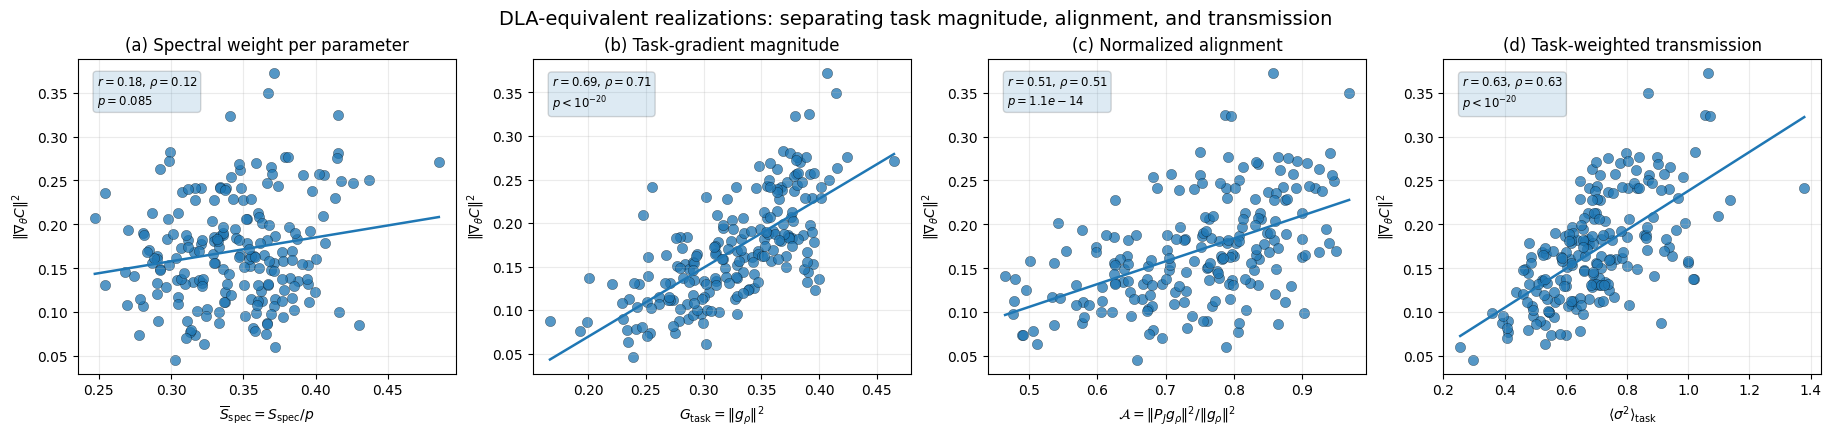

Saved: figures_jacobian_qfim\fig_validationII_jacobian_geometry_permutations.pdf


In [16]:
# Fig. 3: no product S_spec*S_align is interpreted as Eq. (12).
# The four panels separately test parameter-normalized spectrum, task-gradient
# magnitude, normalized directional alignment, and task-weighted transmission.
from scipy.stats import pearsonr, spearmanr

def corr_text(x, y):
    mask=np.isfinite(x)&np.isfinite(y); x=np.asarray(x)[mask]; y=np.asarray(y)[mask]
    return (*pearsonr(x,y), *spearmanr(x,y))

def format_p(p):
    if p < 1e-20: return r"$p<10^{-20}$"
    if p < 1e-3: return rf"$p={p:.1e}$"
    return rf"$p={p:.3f}$"

df=perm_df.copy(); grad=df["grad_norm2"].to_numpy(float)
panel_defs=[
    ("spec_per_param", r"$\overline{S}_{\rm spec}=S_{\rm spec}/p$", "(a) Spectral weight per parameter"),
    ("task_grad_norm2", r"$G_{\rm task}=\|g_\rho\|^2$", "(b) Task-gradient magnitude"),
    ("normalized_alignment", r"$\mathcal{A}=\|P_Jg_\rho\|^2/\|g_\rho\|^2$", "(c) Normalized alignment"),
    ("task_weighted_sigma2", r"$\langle\sigma^2\rangle_{\rm task}$", "(d) Task-weighted transmission"),
]
fig,axes=plt.subplots(1,4,figsize=(18.2,4.25),constrained_layout=True)
for ax,(col,xlabel,title) in zip(axes,panel_defs):
    x=df[col].to_numpy(float); mask=np.isfinite(x)&np.isfinite(grad); xx0=x[mask]; yy0=grad[mask]
    r,p,rho,ps=corr_text(xx0,yy0)
    ax.scatter(xx0,yy0,s=55,alpha=.76,edgecolors='k',linewidths=.25)
    if len(np.unique(xx0))>1:
        coef=np.polyfit(xx0,yy0,1); xx=np.linspace(xx0.min(),xx0.max(),150); ax.plot(xx,coef[0]*xx+coef[1],'-',linewidth=1.8)
    ax.set_xlabel(xlabel); ax.set_ylabel(r"$\|\nabla_\theta C\|^2$"); ax.set_title(title); ax.grid(True,alpha=.25)
    ax.text(.05,.95,rf"$r={r:.2f}$, $\rho={rho:.2f}$"+'\n'+format_p(ps),transform=ax.transAxes,va='top',fontsize=8.4,bbox=dict(boxstyle='round',alpha=.15))
fig.suptitle("DLA-equivalent realizations: separating task magnitude, alignment, and transmission",fontsize=14)
path_pdf=os.path.join(FIG_DIR,"fig_validationII_jacobian_geometry_permutations.pdf")
fig.savefig(path_pdf,bbox_inches='tight'); fig.savefig(path_pdf.replace('.pdf','.png'),dpi=300,bbox_inches='tight'); plt.show()
print('Saved:',path_pdf)


# Validation III — scaling with qubits, depth and cost locality

In [17]:
def _validation_III_worker(task) -> Dict:
    n, depth, fam, cost_name, sample, theta, eps = task

    if fam == "hea":
        ans = hea_ansatz(n, depth, entangler="rzz")
    elif fam == "local":
        ans = local_rxrz_ansatz(n, depth)
    elif fam == "chainA":
        ans = dla_equiv_chain_A(n, depth)
    elif fam == "chainB":
        ans = dla_equiv_chain_B(n, depth)
    else:
        raise ValueError(fam)

    if cost_name == "local_Z1":
        obs = local_Z(n, 0)
    elif cost_name == "global_mixed":
        obs = global_mixed_phase_string(n)
    elif cost_name == "global_Z_symmetry_control":
        obs = global_Z(n)
    else:
        raise ValueError(cost_name)

    diag = modal_diagnostics(ans, np.asarray(theta, float), obs, eps=eps)
    return {
        "n": n,
        "depth": depth,
        "family": fam,
        "cost": cost_name,
        "sample": sample,
        "p": ans.n_params,
        "grad_norm2": diag["grad_norm2"],
        "spec_sum": diag["spec_sum"],
        "spec_per_param": diag["spec_per_param"],
        "align_sum": diag["align_sum"],
        "task_grad_norm2": diag["task_grad_norm2"],
        "normalized_alignment": diag["normalized_alignment"],
        "task_weighted_sigma2": diag["task_weighted_sigma2"],
        "block_sigma2": diag["block_sigma2"],
        "block_task_coeff": diag["block_task_coeff"],
        "block_modal_contrib": diag["block_modal_contrib"],
        "block_multiplicity": diag["block_multiplicity"],
        "sigma_max": diag["sigma_max"],
        "rank_eps": diag["rank_eps"],
        "sigma_min_pos": diag["sigma_min_pos"],
        "active_n": diag["active_n"],
        "active_sigma2_min": diag["active_sigma2_min"],
        "active_sigma2_max": diag["active_sigma2_max"],
        "active_sigma2_ratio": diag["active_sigma2_ratio"],
        "active_sigma2_logspread": diag["active_sigma2_logspread"],
    }


def validation_III_scaling(
    ns=(2,4,6,8,10),
    depths=(2,3,4),
    families=("hea", "local", "chainA", "chainB"),
    n_samples: int = 50,
    seed: int = 40,
    eps: float = 1e-6,
    include_symmetry_control: bool = False,
    n_jobs: Optional[int] = None,
) -> pd.DataFrame:
    """Scaling diagnostics for gradient, spectral energy and alignment.

    Computes independent circuit instances in parallel while preserving the
    original RNG sequence.
    """
    local_rng = np.random.default_rng(seed)
    tasks = []

    for n in ns:
        for L in depths:
            for fam in families:
                if fam == "hea":
                    ans = hea_ansatz(n, L, entangler="rzz")
                elif fam == "local":
                    ans = local_rxrz_ansatz(n, L)
                elif fam == "chainA":
                    ans = dla_equiv_chain_A(n, L)
                elif fam == "chainB":
                    ans = dla_equiv_chain_B(n, L)
                else:
                    raise ValueError(fam)

                cost_names = ["local_Z1", "global_mixed"]
                if include_symmetry_control:
                    cost_names.append("global_Z_symmetry_control")

                for cost_name in cost_names:
                    for s in range(n_samples):
                        theta = local_rng.uniform(-np.pi, np.pi, size=ans.n_params)
                        tasks.append(
                            (int(n), int(L), fam, cost_name, int(s), theta, float(eps))
                        )

    rows = _parallel_map(_validation_III_worker, tasks, n_jobs=n_jobs)
    return (
        pd.DataFrame(rows)
        .sort_values(["n", "depth", "family", "cost", "sample"])
        .reset_index(drop=True)
    )


# Parallelized at the independent-instance level.
valIII_df = validation_III_scaling(
    ns=(2,4,6,8,10),
    depths=(2,3,4),
    n_samples=50,
    n_jobs=PARALLEL_N_JOBS,
)
valIII_df.head()


,n,depth,family,cost,sample,p,grad_norm2,spec_sum,spec_per_param,align_sum,...,block_modal_contrib,block_multiplicity,sigma_max,rank_eps,sigma_min_pos,active_n,active_sigma2_min,active_sigma2_max,active_sigma2_ratio,active_sigma2_logspread
0,2,2,chainA,global_mixed,0,6,2.539807,2.069802,0.344967,1.962083,...,"[2.504806780409696, 0.035000201047792064]","[1, 1]",1.143321,2,0.873281,2,0.762620,1.307182,1.714067,0.234028
1,2,2,chainA,global_mixed,1,6,0.859956,2.247699,0.374617,0.787411,...,"[0.47109422312827715, 0.388861296752304]","[1, 1]",1.171307,2,0.935809,2,0.875739,1.371960,1.566632,0.194967
2,2,2,chainA,global_mixed,2,6,0.865243,1.739459,0.289910,0.928205,...,"[0.6780522941382969, 0.1871906955698889]","[1, 1]",1.004591,2,0.854550,2,0.730256,1.009203,1.381985,0.140503
3,2,2,chainA,global_mixed,3,6,1.901806,1.913609,0.318935,1.668252,...,"[1.6688656576287109, 0.23294024097658347]","[1, 1]",1.134679,2,0.791272,2,0.626112,1.287497,2.056337,0.313094
4,2,2,chainA,global_mixed,4,6,2.201258,2.260929,0.376822,1.464821,...,"[2.201216314312883, 4.1815648222909085e-05]","[1, 1]",1.225878,2,0.870720,2,0.758152,1.502777,1.982156,0.297138


In [18]:
def aggregate_scaling(df: pd.DataFrame) -> pd.DataFrame:
    sem=lambda x: x.std(ddof=1)/np.sqrt(len(x))
    return df.groupby(["n","depth","family","cost"]).agg(
        grad_mean=("grad_norm2","mean"), grad_sem=("grad_norm2",sem),
        spec_mean=("spec_sum","mean"), spec_sem=("spec_sum",sem),
        specpp_mean=("spec_per_param","mean"), specpp_sem=("spec_per_param",sem),
        align_mean=("align_sum","mean"), align_sem=("align_sum",sem),
        gtask_mean=("task_grad_norm2","mean"), gtask_sem=("task_grad_norm2",sem),
        norm_align_mean=("normalized_alignment","mean"), norm_align_sem=("normalized_alignment",sem),
        task_sigma2_mean=("task_weighted_sigma2","mean"), task_sigma2_sem=("task_weighted_sigma2",sem),
        sigma_max_mean=("sigma_max","mean"), rank_mean=("rank_eps","mean"),
    ).reset_index()
valIII_agg=aggregate_scaling(valIII_df); valIII_agg.head()


,n,depth,family,cost,grad_mean,grad_sem,spec_mean,spec_sem,specpp_mean,specpp_sem,align_mean,align_sem,gtask_mean,gtask_sem,norm_align_mean,norm_align_sem,task_sigma2_mean,task_sigma2_sem,sigma_max_mean,rank_mean
0,2,2,chainA,global_mixed,1.565981,0.131901,2.088627,0.058996,0.348104,0.009833,1.325000,0.084483,1.325000,0.084483,1.0,3.286011e-11,1.181763,0.055521,1.157749,2.0
1,2,2,chainA,local_Z1,0.983985,0.084527,2.007301,0.066606,0.334550,0.011101,1.230695,0.094881,1.230695,0.094881,1.0,4.810390e-11,0.786030,0.025607,1.137387,2.0
2,2,2,chainB,global_mixed,0.990824,0.079611,1.338384,0.034601,0.223064,0.005767,1.255525,0.087322,1.255525,0.087322,1.0,8.712942e-12,0.762592,0.024968,0.935960,2.0
3,2,2,chainB,local_Z1,0.992272,0.071116,1.342170,0.040931,0.223695,0.006822,1.301153,0.086034,1.301153,0.086034,1.0,2.216846e-11,0.756016,0.025646,0.930262,2.0
4,2,2,hea,global_mixed,0.864776,0.063222,3.912065,0.057313,0.391207,0.005731,1.680437,0.052548,1.680437,0.052548,1.0,1.812597e-11,0.541565,0.039278,1.135625,6.0


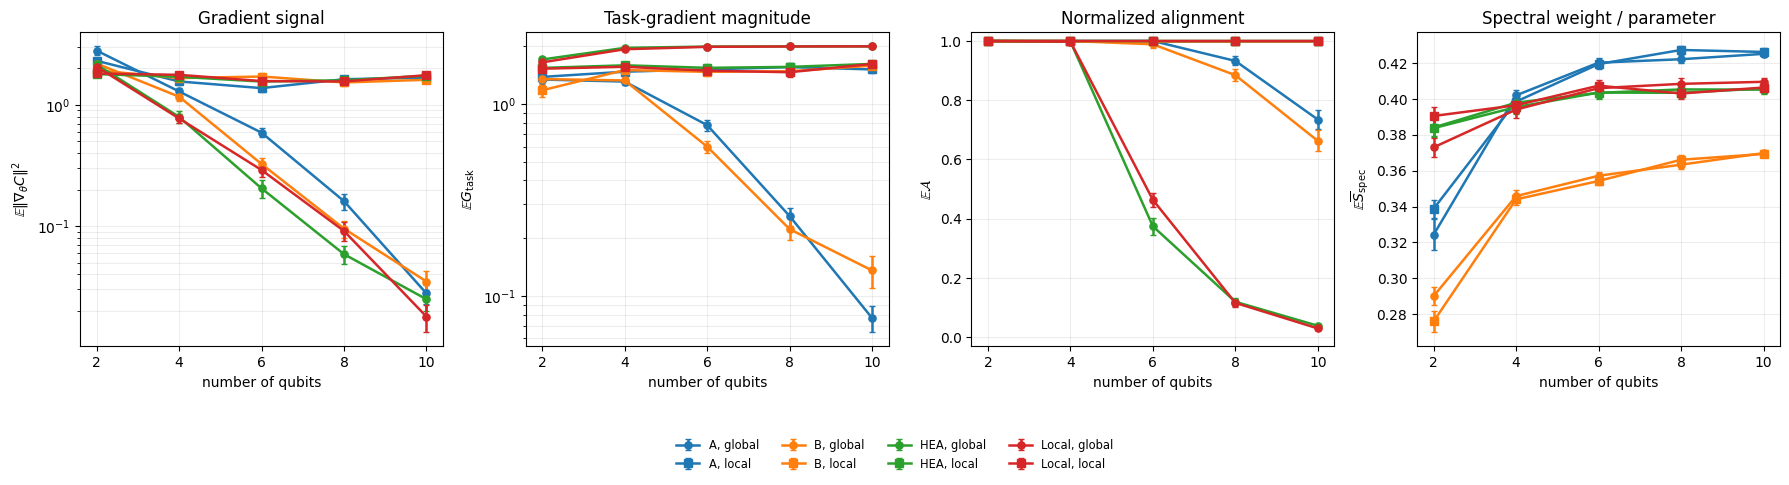

Saved: figures_jacobian_qfim\fig_validationIII_scaling_local_global.pdf


In [19]:
def plot_validation_III_scaling(df: pd.DataFrame, depth: int = 4,
                                filename: str = "fig_validationIII_scaling_local_global.pdf"):
    agg=aggregate_scaling(df); agg=agg[agg["depth"]==depth].copy()
    fig,axes=plt.subplots(1,4,figsize=(18.0,4.5))
    metrics=[
        ("grad_mean","grad_sem",r"$\mathbb{E}\|\nabla_\theta C\|^2$","log","Gradient signal"),
        ("gtask_mean","gtask_sem",r"$\mathbb{E}G_{\rm task}$","log","Task-gradient magnitude"),
        ("norm_align_mean","norm_align_sem",r"$\mathbb{E}\mathcal{A}$","linear","Normalized alignment"),
        ("specpp_mean","specpp_sem",r"$\mathbb{E}\overline{S}_{\rm spec}$","linear","Spectral weight / parameter"),
    ]
    family_labels={"chainA":"A","chainB":"B","hea":"HEA","local":"Local"}
    cost_labels={"global_mixed":"global","local_Z1":"local","global_Z_symmetry_control":"global Z control"}
    family_colors={"chainA":"C0","chainB":"C1","hea":"C2","local":"C3"}
    cost_markers={"global_mixed":"o","local_Z1":"s","global_Z_symmetry_control":"x"}
    legend_handles=[]; legend_labels=[]
    for ax,(m,sem,ylabel,scale,title) in zip(axes,metrics):
        for fam in sorted(agg.family.unique()):
            for cost in sorted(agg.cost.unique()):
                sub=agg[(agg.family==fam)&(agg.cost==cost)].sort_values('n')
                if sub.empty: continue
                label=f"{family_labels.get(fam,fam)}, {cost_labels.get(cost,cost)}"
                eb=ax.errorbar(sub.n,sub[m],yerr=sub[sem].fillna(0),marker=cost_markers.get(cost,'o'),color=family_colors.get(fam),capsize=2.5,linewidth=1.8,markersize=5.2,label=label)
                if m=='grad_mean': legend_handles.append(eb); legend_labels.append(label)
        ax.set_xlabel('number of qubits'); ax.set_ylabel(ylabel); ax.set_title(title); ax.set_yscale(scale); ax.grid(True,which='both',alpha=.22)
        if m=='norm_align_mean': ax.set_ylim(-.03,1.03)
    fig.legend(legend_handles,legend_labels,loc='lower center',bbox_to_anchor=(.5,-.08),ncol=4,frameon=False,fontsize=8.3)
    fig.tight_layout(rect=(0,.09,1,1)); path=os.path.join(FIG_DIR,filename)
    fig.savefig(path,bbox_inches='tight'); fig.savefig(path.replace('.pdf','.png'),dpi=300,bbox_inches='tight'); plt.show(); return path
path_scaling=plot_validation_III_scaling(valIII_df,depth=4); print('Saved:',path_scaling)


# Validation IV — predictive value for actual training

In [20]:
def gradient_descent_train(
    ansatz: AnsatzSpec,
    theta0: np.ndarray,
    observable: SparsePauliOp,
    target: float = -1.0,
    lr: float = 0.08,
    steps: int = 100,
    eps: float = 1e-6,
    threshold: float = 1e-3,
) -> Dict:
    # Loss = 0.5*(C(theta)-target)^2
    theta = theta0.copy()
    history = []
    hit_iter = None
    for t in range(steps):
        c = cost_value(ansatz, theta, observable)
        loss = 0.5*(c - target)**2
        history.append(loss)
        if hit_iter is None and loss < threshold:
            hit_iter = t
        grad_C = finite_difference_gradient(ansatz, theta, observable, eps=eps)
        grad_loss = (c - target) * grad_C
        theta = theta - lr * grad_loss
    c = cost_value(ansatz, theta, observable)
    final_loss = 0.5*(c - target)**2
    if hit_iter is None and final_loss < threshold:
        hit_iter = steps
    return {
        "theta_final": theta,
        "final_cost": c,
        "final_loss": float(final_loss),
        "hit_iter": hit_iter if hit_iter is not None else np.nan,
        "success": bool(final_loss < threshold),
        "history": np.array(history),
    }


def _validation_IV_worker(task) -> Dict:
    instance, fam, cost_name, n, depth, theta0, eps = task

    if fam == "hea":
        ans = hea_ansatz(n, depth, entangler="rzz")
    elif fam == "local":
        ans = local_rxrz_ansatz(n, depth)
    elif fam == "chainA":
        ans = dla_equiv_chain_A(n, depth)
    elif fam == "chainB":
        ans = dla_equiv_chain_B(n, depth)
    else:
        raise ValueError(fam)

    if cost_name == "local_Z1":
        obs = local_Z(n, 0)
    elif cost_name == "global_mixed":
        obs = global_mixed_phase_string(n)
    else:
        raise ValueError(cost_name)

    theta0 = np.asarray(theta0, float)
    diag0 = modal_diagnostics(ans, theta0, obs, eps=eps)
    train = gradient_descent_train(
        ans, theta0, obs,
        target=-1.0, lr=0.08, steps=100, eps=eps, threshold=1e-3
    )

    return {
        "instance": instance,
        "family": fam,
        "cost": cost_name,
        "n": n,
        "depth": depth,
        "p": ans.n_params,
        "init_grad_norm2": diag0["grad_norm2"],
        "init_sigma_max": diag0["sigma_max"],
        "init_spec_sum": diag0["spec_sum"],
        "init_spec_per_param": diag0["spec_per_param"],
        "init_align_sum": diag0["align_sum"],
        "init_task_grad_norm2": diag0["task_grad_norm2"],
        "init_normalized_alignment": diag0["normalized_alignment"],
        "init_task_weighted_sigma2": diag0["task_weighted_sigma2"],
        "init_block_sigma2": diag0["block_sigma2"],
        "init_block_task_coeff": diag0["block_task_coeff"],
        "init_block_modal_contrib": diag0["block_modal_contrib"],
        "init_block_multiplicity": diag0["block_multiplicity"],
        "init_rank_eps": diag0["rank_eps"],
        "active_n": diag0["active_n"],
        "active_sigma2_min": diag0["active_sigma2_min"],
        "active_sigma2_max": diag0["active_sigma2_max"],
        "active_sigma2_ratio": diag0["active_sigma2_ratio"],
        "active_sigma2_logspread": diag0["active_sigma2_logspread"],
        "final_loss": train["final_loss"],
        "success": train["success"],
        "hit_iter": train["hit_iter"],
    }


def validation_IV_predictive(
    n_instances: int = 200,
    n: int = 6,
    depth: int = 4,
    seed: int = 50,
    eps: float = 1e-6,
    n_jobs: Optional[int] = None,
) -> pd.DataFrame:
    """Predictive validation at nontrivial depth, parallelized by instance.

    Random families, tasks and initial points are still generated serially from
    the same RNG seed before parallel execution, preserving reproducibility.
    """
    local_rng = np.random.default_rng(seed)
    tasks = []
    family_names = ["hea", "local", "chainA", "chainB"]

    for s in range(n_instances):
        fam = local_rng.choice(family_names)

        if local_rng.random() < 0.5:
            cost_name = "local_Z1"
        else:
            cost_name = "global_mixed"

        if fam == "hea":
            p = hea_ansatz(n, depth, entangler="rzz").n_params
        elif fam == "local":
            p = local_rxrz_ansatz(n, depth).n_params
        elif fam == "chainA":
            p = dla_equiv_chain_A(n, depth).n_params
        else:
            p = dla_equiv_chain_B(n, depth).n_params

        theta0 = local_rng.uniform(-np.pi, np.pi, size=p)
        tasks.append(
            (int(s), fam, cost_name, int(n), int(depth), theta0, float(eps))
        )

    rows = _parallel_map(_validation_IV_worker, tasks, n_jobs=n_jobs)
    return pd.DataFrame(rows).sort_values("instance").reset_index(drop=True)


valIV_df = validation_IV_predictive(
    n_instances=200, n=6, depth=4, n_jobs=PARALLEL_N_JOBS
)
valIV_df.head()


,instance,family,cost,n,depth,p,init_grad_norm2,init_sigma_max,init_spec_sum,init_spec_per_param,...,init_block_multiplicity,init_rank_eps,active_n,active_sigma2_min,active_sigma2_max,active_sigma2_ratio,active_sigma2_logspread,final_loss,success,hit_iter
0,0,chainB,global_mixed,6,4,44,0.066590,1.448065,16.404261,0.372824,...,"[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, ...",30,29,0.000004,2.096891,5.722756e+05,5.757605,0.008055,False,NaN
1,1,chainB,local_Z1,6,4,44,0.811227,1.386562,14.389064,0.327024,...,"[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, ...",29,22,0.001742,1.922554,1.103680e+03,3.042843,0.000274,True,52.0
2,2,local,local_Z1,6,4,68,1.513716,1.762681,27.526114,0.404796,...,"[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, ...",64,38,0.000736,3.107043,4.222705e+03,3.625591,0.002082,False,NaN
3,3,chainB,local_Z1,6,4,44,1.430068,1.328029,17.068842,0.387928,...,"[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, ...",30,27,0.008919,1.763661,1.977310e+02,2.296075,0.001654,False,NaN
4,4,hea,global_mixed,6,4,68,0.532571,1.824515,27.990624,0.411627,...,"[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, ...",64,60,0.000001,3.328855,3.220922e+06,6.507980,0.004548,False,NaN


In [21]:
# Confirm that the gradient-active singular values are not all identical.
# If active_sigma2_logspread is near zero for most rows, the experiment is
# effectively testing alignment only.

def summarize_active_spectrum(df: pd.DataFrame) -> pd.DataFrame:
    cols = [
        "active_n",
        "active_sigma2_min",
        "active_sigma2_max",
        "active_sigma2_ratio",
        "active_sigma2_logspread",
    ]
    summary = df[cols].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9])
    return summary

active_summary_IV = summarize_active_spectrum(valIV_df)
display(active_summary_IV)

print("Median active sigma^2 log-spread:", np.nanmedian(valIV_df["active_sigma2_logspread"]))
print("Fraction with active log-spread > 0.25:", np.mean(valIV_df["active_sigma2_logspread"] > 0.25))


,active_n,active_sigma2_min,active_sigma2_max,active_sigma2_ratio,active_sigma2_logspread
count,200.000000,2.000000e+02,200.000000,2.000000e+02,200.000000
mean,37.085000,1.673660e-03,2.642526,2.769584e+07,4.691037
std,12.305482,6.611351e-03,0.644400,1.800243e+08,1.758521
min,17.000000,1.902387e-09,1.595018,3.182273e+01,1.502737
10%,25.000000,2.084897e-07,1.839926,6.920877e+02,2.840160
25%,28.000000,1.556165e-06,2.096343,1.782806e+03,3.250978
50%,30.000000,2.597099e-04,2.622973,8.651792e+03,3.936220
75%,46.250000,1.429647e-03,3.098210,1.600413e+06,6.204174
90%,58.000000,3.533143e-03,3.480629,1.236072e+07,7.091322
max,63.000000,8.644280e-02,4.306942,2.088346e+09,9.319802


Median active sigma^2 log-spread: 3.9362195166208185
Fraction with active log-spread > 0.25: 1.0


In [22]:
def correlation_table(df: pd.DataFrame, predictors: Sequence[str], target: str = "final_loss") -> pd.DataFrame:
    rows=[]
    for p in predictors:
        sub=df[[p,target]].replace([np.inf,-np.inf],np.nan).dropna()
        rows.append({"predictor":p,"target":target,"pearson":sub.corr(method='pearson').iloc[0,1],"spearman":sub.corr(method='spearman').iloc[0,1]})
    return pd.DataFrame(rows)
pred_cols=["init_grad_norm2","init_task_grad_norm2","init_normalized_alignment","init_task_weighted_sigma2","init_sigma_max","init_spec_sum","init_spec_per_param","init_align_sum","init_rank_eps"]
correlation_table(valIV_df,pred_cols,target="final_loss")


,predictor,target,pearson,spearman
0,init_grad_norm2,final_loss,-0.110938,-0.691702
1,init_task_grad_norm2,final_loss,0.071446,0.035224
2,init_normalized_alignment,final_loss,-0.188401,-0.321784
3,init_task_weighted_sigma2,final_loss,-0.153470,-0.699449
4,init_sigma_max,final_loss,0.106076,-0.047794
5,init_spec_sum,final_loss,0.026137,-0.001259
6,init_spec_per_param,final_loss,-0.089090,0.049711
7,init_align_sum,final_loss,-0.089370,-0.482477
8,init_rank_eps,final_loss,0.068248,0.004285


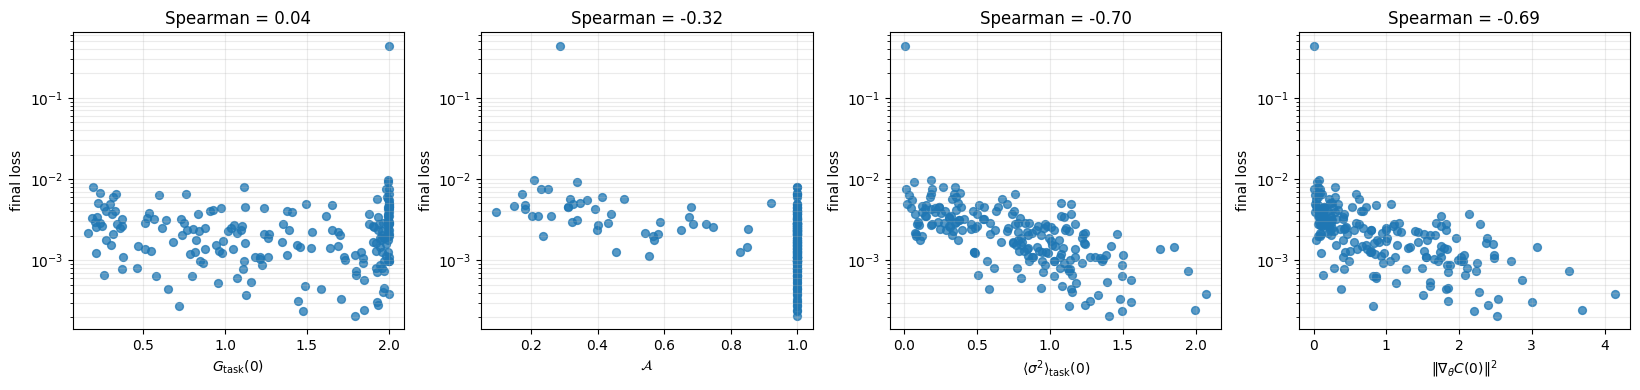

'figures_jacobian_qfim\\fig_validationIV_predictive_training.pdf'

In [23]:
def plot_validation_IV_predictive(df: pd.DataFrame, filename: str = "fig_validationIV_predictive_training.pdf"):
    fig,axes=plt.subplots(1,4,figsize=(16.5,4.0))
    panels=[("init_task_grad_norm2",r"$G_{\rm task}(0)$"),("init_normalized_alignment",r"$\mathcal{A}$"),("init_task_weighted_sigma2",r"$\langle\sigma^2\rangle_{\rm task}(0)$"),("init_grad_norm2",r"$\|\nabla_\theta C(0)\|^2$")]
    for ax,(col,xlabel) in zip(axes,panels):
        sub=df[[col,'final_loss']].replace([np.inf,-np.inf],np.nan).dropna(); ax.scatter(sub[col],sub.final_loss,s=32,alpha=.75)
        ax.set_xlabel(xlabel); ax.set_ylabel('final loss'); ax.set_yscale('log'); ax.grid(True,which='both',alpha=.25)
        rho=sub.corr(method='spearman').iloc[0,1]; ax.set_title(f"Spearman = {rho:.2f}")
    fig.tight_layout(); path=os.path.join(FIG_DIR,filename); fig.savefig(path,bbox_inches='tight'); fig.savefig(path.replace('.pdf','.png'),dpi=300,bbox_inches='tight'); plt.show(); return path
plot_validation_IV_predictive(valIV_df)


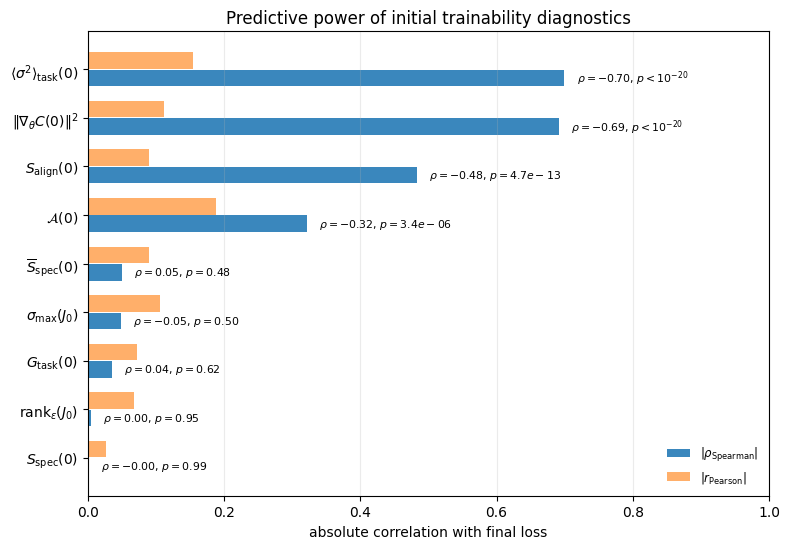

,predictor,pearson,pearson_p,spearman,spearman_p
6,init_spec_sum,0.026137,0.713336,-0.001259,9.858887e-01
7,init_rank_eps,0.068248,0.336932,0.004285,9.519816e-01
1,init_task_grad_norm2,0.071446,0.314730,0.035224,6.204786e-01
8,init_sigma_max,0.106076,0.134927,-0.047794,5.015458e-01
5,init_spec_per_param,-0.089090,0.209653,0.049711,4.845215e-01
2,init_normalized_alignment,-0.188401,0.007548,-0.321784,3.378324e-06
4,init_align_sum,-0.089370,0.208220,-0.482477,4.672665e-13
0,init_grad_norm2,-0.110938,0.117843,-0.691702,8.375106e-30
3,init_task_weighted_sigma2,-0.153470,0.030032,-0.699449,1.048122e-30


Saved: figures_jacobian_qfim\fig_validationIV_predictor_ranking.pdf


In [24]:
from scipy.stats import pearsonr, spearmanr

def validation_IV_predictor_ranking(
    df: pd.DataFrame,
    target: str = "final_loss",
    filename: str = "fig_validationIV_predictor_ranking.pdf"
):
    predictors = [
        ("init_grad_norm2", r"$\|\nabla_{\theta} C(0)\|^2$"),
        ("init_task_grad_norm2", r"$G_{\rm task}(0)$"),
        ("init_normalized_alignment", r"$\mathcal{A}(0)$"),
        ("init_task_weighted_sigma2", r"$\langle \sigma^2\rangle_{\rm task}(0)$"),
        ("init_align_sum", r"$S_{\rm align}(0)$"),
        ("init_spec_per_param", r"$\overline{S}_{\rm spec}(0)$"),
        ("init_spec_sum", r"$S_{\rm spec}(0)$"),
        ("init_rank_eps", r"$\mathrm{rank}_{\epsilon}(J_0)$"),
        ("init_sigma_max", r"$\sigma_{\max}(J_0)$"),
    ]

    rows = []

    for col, label in predictors:
        sub = (
            df[[col, target]]
            .replace([np.inf, -np.inf], np.nan)
            .dropna()
        )

        x = sub[col].to_numpy(float)
        y = sub[target].to_numpy(float)

        r, p = pearsonr(x, y)
        rho, ps = spearmanr(x, y)

        rows.append(
            dict(
                predictor=col,
                label=label,
                pearson=r,
                pearson_abs=abs(r),
                pearson_p=p,
                spearman=rho,
                spearman_abs=abs(rho),
                spearman_p=ps,
            )
        )

    corr_df = (
        pd.DataFrame(rows)
        .sort_values("spearman_abs", ascending=True)
    )

    fig, ax = plt.subplots(figsize=(8.0, 5.6))
    y = np.arange(len(corr_df))

    ax.barh(
        y - .18,
        corr_df.spearman_abs,
        height=.34,
        label=r"$|\rho_{\rm Spearman}|$",
        alpha=.88
    )

    ax.barh(
        y + .18,
        corr_df.pearson_abs,
        height=.34,
        label=r"$|r_{\rm Pearson}|$",
        alpha=.62
    )

    ax.set_yticks(y)
    ax.set_yticklabels(corr_df.label)
    ax.set_xlabel("absolute correlation with final loss")
    ax.set_xlim(0, 1)
    ax.grid(True, axis="x", alpha=.25)
    ax.legend(frameon=False, loc="lower right", fontsize=8.5)
    ax.set_title("Predictive power of initial trainability diagnostics")

    for i, (_, row) in enumerate(corr_df.iterrows()):
        pv = row.spearman_p

        pt = (
            r"$p<10^{-20}$"
            if pv < 1e-20
            else (
                rf"$p={pv:.1e}$"
                if pv < 1e-3
                else rf"$p={pv:.2f}$"
            )
        )

        ax.text(
            row.spearman_abs + .018,
            i - .18,
            rf"$\rho={row.spearman:.2f}$, {pt}",
            va="center",
            fontsize=7.8
        )

    fig.tight_layout()

    path = os.path.join(FIG_DIR, filename)

    fig.savefig(path, bbox_inches="tight")
    fig.savefig(
        path.replace(".pdf", ".png"),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    return corr_df, path


valIV_corr_df, path_valIV_ranking = validation_IV_predictor_ranking(valIV_df)

display(
    valIV_corr_df[
        ["predictor", "pearson", "pearson_p", "spearman", "spearman_p"]
    ]
)

print("Saved:", path_valIV_ranking)

In [25]:
predictors=[
    ("init_sigma_max",r"$\sigma_{\max}(J_0)$"),("init_spec_sum",r"$S_{\rm spec}(0)$"),("init_spec_per_param",r"$\overline{S}_{\rm spec}(0)$"),
    ("init_rank_eps",r"$\mathrm{rank}_\epsilon(J_0)$"),("init_align_sum",r"$S_{\rm align}(0)$"),("init_task_grad_norm2",r"$G_{\rm task}(0)$"),
    ("init_normalized_alignment",r"$\mathcal A(0)$"),("init_task_weighted_sigma2",r"$\langle\sigma^2\rangle_{\rm task}(0)$"),("init_grad_norm2",r"$\|\nabla_\theta C(0)\|^2$")]
rows=[]
for col,label in predictors:
    sub=valIV_df[[col,'final_loss']].replace([np.inf,-np.inf],np.nan).dropna(); r,p=pearsonr(sub[col],sub.final_loss); rho,ps=spearmanr(sub[col],sub.final_loss)
    rows.append({"Predictor":label,"Pearson":r,"Pearson p":p,"Spearman":rho,"Spearman p":ps})
corr_table=pd.DataFrame(rows); corr_table


,Predictor,Pearson,Pearson p,Spearman,Spearman p
0,$\sigma_{\max}(J_0)$,0.106076,0.134927,-0.047794,5.015458e-01
1,$S_{\rm spec}(0)$,0.026137,0.713336,-0.001259,9.858887e-01
2,$\overline{S}_{\rm spec}(0)$,-0.089090,0.209653,0.049711,4.845215e-01
3,$\mathrm{rank}_\epsilon(J_0)$,0.068248,0.336932,0.004285,9.519816e-01
4,$S_{\rm align}(0)$,-0.089370,0.208220,-0.482477,4.672665e-13
5,$G_{\rm task}(0)$,0.071446,0.314730,0.035224,6.204786e-01
6,$\mathcal A(0)$,-0.188401,0.007548,-0.321784,3.378324e-06
7,$\langle\sigma^2\rangle_{\rm task}(0)$,-0.153470,0.030032,-0.699449,1.048122e-30
8,$\|\nabla_\theta C(0)\|^2$,-0.110938,0.117843,-0.691702,8.375106e-30


# Robustness controls

This section adds additional robustness checks **without replacing the main-paper experiments
above**: balanced predictive cohorts, optimizer/hyperparameter sensitivity, paired significance
tests, and numerical-sensitivity checks.

### Parallel execution

The expensive finite-difference workloads are parallelized at the **independent circuit-instance
level**, not across the coordinates of one gradient. This preserves the numerical experiment
exactly while avoiding repeated process synchronization inside every optimization step.
`PARALLEL_N_JOBS` (set above) controls the number of worker processes; BLAS/OpenMP is restricted
to one thread per worker to prevent oversubscription.

Long-running stages write checkpoints **only from the parent process** after each completed
parallel batch, so interrupted runs can be resumed safely.

The controls cover:

- balanced `family × task` predictive cohorts and stratified correlations;
- optimizer / learning-rate / iteration / success-threshold sensitivity;
- paired Wilcoxon tests for Figure 2;
- target-reachability checks;
- finite-difference-step and rank-threshold sensitivity.


In [26]:
import json
# ==============================================================
# Robustness-control production settings
# ==============================================================

ROBUST_FAST = False
ROBUST_DIR = "robustness_controls"
os.makedirs(ROBUST_DIR, exist_ok=True)

# Parallelization is performed at the independent circuit-instance level.
# On an Intel Core i5-13600KF (14 physical cores / 20 logical threads),
# 12 worker processes are a good production default.
ROBUST_N_JOBS = PARALLEL_N_JOBS
ROBUST_PARALLEL_BATCH = max(2 * ROBUST_N_JOBS, 12)

if ROBUST_FAST:
    ROBUST_PER_CELL = 2
    ROBUST_SENS_PER_CELL = 1
    ROBUST_NUMERIC_PER_CELL = 1
    ROBUST_MAX_STEPS = 20
    ROBUST_CHECK_STEPS = (10, 20)
else:
    # Balanced main control: 4 families × 2 tasks × 25 = 200 instances.
    ROBUST_PER_CELL = 25
    # Same fixed instances are reused for all optimizer/hyperparameter settings.
    ROBUST_SENS_PER_CELL = 10
    ROBUST_NUMERIC_PER_CELL = 4
    ROBUST_MAX_STEPS = 200
    ROBUST_CHECK_STEPS = (50, 100, 200)

ROBUST_N = 6
ROBUST_DEPTH = 4
ROBUST_SEED = 600
ROBUST_EPS = 1e-6
ROBUST_RANK_TOL = 1e-10
ROBUST_TARGET = -1.0
ROBUST_SUCCESS_THRESHOLDS = (1e-2, 1e-3, 1e-4)

# Main manuscript configuration + compact sensitivity grid.
ROBUST_TRAIN_CONFIGS = [
    {"optimizer": "gd",   "lr": 0.04, "label": "GD_lr0.04"},
    {"optimizer": "gd",   "lr": 0.08, "label": "GD_lr0.08"},
    {"optimizer": "gd",   "lr": 0.12, "label": "GD_lr0.12"},
    {"optimizer": "adam", "lr": 0.03, "label": "Adam_lr0.03"},
]

print("Robustness controls:", "FAST" if ROBUST_FAST else "PRODUCTION")
print("Balanced instances:", 8 * ROBUST_PER_CELL)
print("Sensitivity instances:", 8 * ROBUST_SENS_PER_CELL)
print("Max training steps:", ROBUST_MAX_STEPS)
print("Parallel workers:", ROBUST_N_JOBS)
print("Checkpoint batch size:", ROBUST_PARALLEL_BATCH)


Robustness controls: PRODUCTION
Balanced instances: 200
Sensitivity instances: 80
Max training steps: 200
Parallel workers: 12
Checkpoint batch size: 24


In [27]:
# ==============================================================
# Balanced cohort, training helpers, and stratified statistics
# ==============================================================

from scipy.stats import pearsonr, spearmanr, wilcoxon

ROBUST_PREDICTORS = [
    "init_sigma_max",
    "init_spec_sum",
    "init_spec_per_param",
    "init_rank_eps",
    "init_task_grad_norm2",
    "init_normalized_alignment",
    "init_align_sum",
    "init_task_weighted_sigma2",
    "init_grad_norm2",
]


def _robust_family_ansatz(family: str, n: int = ROBUST_N, depth: int = ROBUST_DEPTH) -> AnsatzSpec:
    builders = {
        "hea": lambda: hea_ansatz(n, depth, entangler="rzz"),
        "local": lambda: local_rxrz_ansatz(n, depth),
        "chainA": lambda: dla_equiv_chain_A(n, depth),
        "chainB": lambda: dla_equiv_chain_B(n, depth),
    }
    return builders[family]()


def _robust_observable(cost_name: str, n: int = ROBUST_N) -> SparsePauliOp:
    if cost_name == "local_Z1":
        return local_Z(n, 0)
    if cost_name == "global_mixed":
        return global_mixed_phase_string(n)
    raise ValueError(f"Unknown cost: {cost_name}")


def _robust_cohort_worker(task) -> Dict:
    family = task["family"]
    cost_name = task["cost"]
    n = int(task["n"])
    depth = int(task["depth"])
    theta0 = np.asarray(task["theta0"], float)

    ans = _robust_family_ansatz(family, n=n, depth=depth)
    obs = _robust_observable(cost_name, n=n)
    diag0 = modal_diagnostics(
        ans, theta0, obs,
        eps=float(task["eps"]),
        rank_tol=float(task["rank_tol"]),
    )

    return {
        "instance": int(task["instance"]),
        "rep": int(task["rep"]),
        "family": family,
        "cost": cost_name,
        "n": n,
        "depth": depth,
        "p": ans.n_params,
        "theta0": theta0,
        "theta0_json": json.dumps(theta0.tolist()),
        "init_grad_norm2": diag0["grad_norm2"],
        "init_sigma_max": diag0["sigma_max"],
        "init_spec_sum": diag0["spec_sum"],
        "init_spec_per_param": diag0["spec_per_param"],
        "init_align_sum": diag0["align_sum"],
        "init_task_grad_norm2": diag0["task_grad_norm2"],
        "init_normalized_alignment": diag0["normalized_alignment"],
        "init_task_weighted_sigma2": diag0["task_weighted_sigma2"],
        "init_rank_eps": diag0["rank_eps"],
    }


def _save_cohort_checkpoint(rows, checkpoint_csv: Optional[str]):
    if not checkpoint_csv:
        return
    out = pd.DataFrame(rows).sort_values("instance").copy()
    if "theta0" in out.columns:
        out = out.drop(columns=["theta0"])
    out.to_csv(checkpoint_csv, index=False)


def build_balanced_predictive_cohort(
    per_cell: int = ROBUST_PER_CELL,
    n: int = ROBUST_N,
    depth: int = ROBUST_DEPTH,
    seed: int = ROBUST_SEED,
    eps: float = ROBUST_EPS,
    rank_tol: float = ROBUST_RANK_TOL,
    n_jobs: int = ROBUST_N_JOBS,
    checkpoint_csv: Optional[str] = None,
) -> pd.DataFrame:
    """Balanced 4-family × 2-task cohort, parallelized by independent instance.

    Initial points are generated serially before dispatch, so changing n_jobs does
    not change the random sample.  The parent process alone writes checkpoints.
    """
    local_rng = np.random.default_rng(seed)
    all_tasks = []
    instance = 0

    # Generate the complete deterministic task list in the parent process.
    for family in ("hea", "local", "chainA", "chainB"):
        ans = _robust_family_ansatz(family, n=n, depth=depth)
        for cost_name in ("local_Z1", "global_mixed"):
            for rep in range(per_cell):
                theta0 = local_rng.uniform(-np.pi, np.pi, size=ans.n_params)
                all_tasks.append({
                    "instance": instance,
                    "rep": rep,
                    "family": family,
                    "cost": cost_name,
                    "n": n,
                    "depth": depth,
                    "theta0": theta0,
                    "eps": eps,
                    "rank_tol": rank_tol,
                })
                instance += 1

    rows = []
    completed = set()

    if checkpoint_csv and os.path.exists(checkpoint_csv):
        try:
            prev = pd.read_csv(checkpoint_csv).drop_duplicates("instance", keep="last")
            if "theta0_json" in prev.columns:
                prev["theta0"] = prev["theta0_json"].map(
                    lambda s: np.asarray(json.loads(s), dtype=float)
                )
            rows = prev.to_dict("records")
            completed = set(int(x) for x in prev["instance"].tolist())
            print(f"Balanced cohort: resuming with {len(completed)} completed instances")
        except Exception as exc:
            print(f"Balanced cohort: could not read checkpoint ({exc}); starting fresh")
            rows = []
            completed = set()

    pending = [t for t in all_tasks if int(t["instance"]) not in completed]
    total = len(all_tasks)

    for batch in _task_batches(pending, ROBUST_PARALLEL_BATCH):
        new_rows = _parallel_map(
            _robust_cohort_worker,
            batch,
            n_jobs=n_jobs,
        )
        rows.extend(new_rows)
        _save_cohort_checkpoint(rows, checkpoint_csv)
        print(f"Balanced cohort: {len(rows)}/{total}")

    out = pd.DataFrame(rows).sort_values("instance").reset_index(drop=True)
    return out


def train_with_checkpoints(
    ansatz: AnsatzSpec,
    theta0: np.ndarray,
    observable: SparsePauliOp,
    target: float = ROBUST_TARGET,
    optimizer: str = "gd",
    lr: float = 0.08,
    max_steps: int = ROBUST_MAX_STEPS,
    checkpoints: Sequence[int] = ROBUST_CHECK_STEPS,
    eps: float = ROBUST_EPS,
    beta1: float = 0.9,
    beta2: float = 0.999,
    adam_eps: float = 1e-8,
) -> Dict:
    """Train once up to max_steps and record loss/cost at requested checkpoints."""
    theta = np.array(theta0, dtype=float, copy=True)
    m = np.zeros_like(theta)
    v = np.zeros_like(theta)
    checkpoints = tuple(sorted(set(int(x) for x in checkpoints if int(x) > 0)))
    out = {}

    for step in range(1, max_steps + 1):
        c = cost_value(ansatz, theta, observable)
        grad_c = finite_difference_gradient(ansatz, theta, observable, eps=eps)
        grad_loss = (c - target) * grad_c

        if optimizer.lower() == "gd":
            theta -= lr * grad_loss
        elif optimizer.lower() == "adam":
            m = beta1 * m + (1.0 - beta1) * grad_loss
            v = beta2 * v + (1.0 - beta2) * (grad_loss ** 2)
            mhat = m / (1.0 - beta1 ** step)
            vhat = v / (1.0 - beta2 ** step)
            theta -= lr * mhat / (np.sqrt(vhat) + adam_eps)
        else:
            raise ValueError(f"Unsupported optimizer: {optimizer}")

        if step in checkpoints:
            c_after = cost_value(ansatz, theta, observable)
            loss_after = 0.5 * (c_after - target) ** 2
            out[f"cost_{step}"] = float(c_after)
            out[f"loss_{step}"] = float(loss_after)

    c_final = cost_value(ansatz, theta, observable)
    out["theta_final"] = theta
    out["final_cost"] = float(c_final)
    out["final_loss"] = float(0.5 * (c_final - target) ** 2)
    return out


def _robust_training_worker(task) -> Dict:
    row = task["row"]
    ans = _robust_family_ansatz(
        row["family"], int(row["n"]), int(row["depth"])
    )
    obs = _robust_observable(row["cost"], int(row["n"]))

    train = train_with_checkpoints(
        ans,
        np.asarray(row["theta0"], dtype=float),
        obs,
        target=float(task["target"]),
        optimizer=task["optimizer"],
        lr=float(task["lr"]),
        max_steps=int(task["max_steps"]),
        checkpoints=tuple(task["checkpoints"]),
        eps=float(task["eps"]),
    )

    rec = {
        "instance": int(row["instance"]),
        "family": row["family"],
        "cost": row["cost"],
        "n": int(row["n"]),
        "depth": int(row["depth"]),
        "optimizer": task["optimizer"],
        "lr": float(task["lr"]),
        "config": task["label"],
        "final_cost": train["final_cost"],
        "final_loss": train["final_loss"],
    }
    for step in task["checkpoints"]:
        if f"loss_{step}" in train:
            rec[f"loss_{step}"] = train[f"loss_{step}"]
            rec[f"cost_{step}"] = train[f"cost_{step}"]
    return rec


def run_training_configuration(
    cohort: pd.DataFrame,
    optimizer: str,
    lr: float,
    label: str,
    max_steps: int = ROBUST_MAX_STEPS,
    checkpoints: Sequence[int] = ROBUST_CHECK_STEPS,
    target: float = ROBUST_TARGET,
    eps: float = ROBUST_EPS,
    checkpoint_csv: Optional[str] = None,
    n_jobs: int = ROBUST_N_JOBS,
) -> pd.DataFrame:
    """Run one optimizer configuration in parallel with parent-only checkpointing."""
    rows = []
    completed = set()

    if checkpoint_csv and os.path.exists(checkpoint_csv):
        try:
            prev = pd.read_csv(checkpoint_csv).drop_duplicates("instance", keep="last")
            rows = prev.to_dict("records")
            completed = set(int(x) for x in prev["instance"].tolist())
            print(f"{label}: resuming with {len(completed)} completed instances")
        except Exception as exc:
            print(f"{label}: could not read checkpoint ({exc}); starting fresh")

    tasks = []
    for _, row in cohort.reset_index(drop=True).iterrows():
        if int(row.instance) in completed:
            continue
        row_dict = row.to_dict()
        row_dict["theta0"] = np.asarray(row.theta0, dtype=float)
        tasks.append({
            "row": row_dict,
            "optimizer": optimizer,
            "lr": lr,
            "label": label,
            "max_steps": max_steps,
            "checkpoints": tuple(checkpoints),
            "target": target,
            "eps": eps,
        })

    total = len(cohort)

    for batch in _task_batches(tasks, ROBUST_PARALLEL_BATCH):
        new_rows = _parallel_map(
            _robust_training_worker,
            batch,
            n_jobs=n_jobs,
        )
        rows.extend(new_rows)
        rows = (
            pd.DataFrame(rows)
            .drop_duplicates("instance", keep="last")
            .sort_values("instance")
            .to_dict("records")
        )

        if checkpoint_csv:
            pd.DataFrame(rows).to_csv(checkpoint_csv, index=False)
        print(f"{label}: {len(rows)}/{total}")

    return pd.DataFrame(rows).sort_values("instance").reset_index(drop=True)


def _safe_corr(x, y, method="spearman"):
    x = np.asarray(x, float)
    y = np.asarray(y, float)
    mask = np.isfinite(x) & np.isfinite(y)
    x = x[mask]
    y = y[mask]
    if len(x) < 4 or np.nanstd(x) == 0 or np.nanstd(y) == 0:
        return np.nan, np.nan, len(x)
    if method == "spearman":
        r, p = spearmanr(x, y)
    else:
        r, p = pearsonr(x, y)
    return float(r), float(p), len(x)


def stratified_correlation_table(
    df: pd.DataFrame,
    predictors: Sequence[str] = ROBUST_PREDICTORS,
    target: str = "final_loss",
) -> pd.DataFrame:
    """Pooled, task-stratified, family-stratified, and family-by-task correlations."""
    rows = []
    group_specs = [
        ("pooled", None),
        ("task", ["cost"]),
        ("family", ["family"]),
        ("family_task", ["family", "cost"]),
    ]
    for level, keys in group_specs:
        groups = [("all", df)] if keys is None else list(df.groupby(keys, dropna=False))
        for key, g in groups:
            if isinstance(key, tuple):
                stratum = " | ".join(map(str, key))
            else:
                stratum = str(key)
            for pred in predictors:
                rho, ps, n_s = _safe_corr(g[pred], g[target], "spearman")
                r, pp, _ = _safe_corr(g[pred], g[target], "pearson")
                rows.append({
                    "level": level,
                    "stratum": stratum,
                    "predictor": pred,
                    "n": n_s,
                    "pearson": r,
                    "pearson_p": pp,
                    "spearman": rho,
                    "spearman_p": ps,
                })
    return pd.DataFrame(rows)


def partial_spearman(x, y, z):
    """Partial Spearman: Pearson correlation of rank residuals after removing rank(z)."""
    tmp = pd.DataFrame({"x": x, "y": y, "z": z}).replace([np.inf, -np.inf], np.nan).dropna()
    if len(tmp) < 6:
        return np.nan, np.nan, len(tmp)
    rx = tmp.x.rank().to_numpy(float)
    ry = tmp.y.rank().to_numpy(float)
    rz = tmp.z.rank().to_numpy(float)
    Z = np.column_stack([np.ones(len(rz)), rz])
    bx = np.linalg.lstsq(Z, rx, rcond=None)[0]
    by = np.linalg.lstsq(Z, ry, rcond=None)[0]
    ex = rx - Z @ bx
    ey = ry - Z @ by
    r, p = pearsonr(ex, ey)
    return float(r), float(p), len(tmp)


def stratified_partial_alignment(df: pd.DataFrame, target: str = "final_loss") -> pd.DataFrame:
    rows = []
    group_specs = [
        ("pooled", None),
        ("task", ["cost"]),
        ("family", ["family"]),
        ("family_task", ["family", "cost"]),
    ]
    for level, keys in group_specs:
        groups = [("all", df)] if keys is None else list(df.groupby(keys, dropna=False))
        for key, g in groups:
            stratum = " | ".join(map(str, key)) if isinstance(key, tuple) else str(key)
            for pred in ("init_normalized_alignment", "init_align_sum"):
                r, p, n_s = partial_spearman(g[pred], g[target], g["init_task_grad_norm2"])
                rows.append({
                    "level": level,
                    "stratum": stratum,
                    "predictor": pred,
                    "control": "init_task_grad_norm2",
                    "n": n_s,
                    "partial_spearman": r,
                    "p": p,
                })
    return pd.DataFrame(rows)


In [28]:
# ==============================================================
# Paired significance tests for Figure 2
# ==============================================================

def _holm_adjust(pvals: Sequence[float]) -> np.ndarray:
    p = np.asarray(pvals, float)
    out = np.full(len(p), np.nan)
    finite = np.isfinite(p)
    idx = np.where(finite)[0]
    if len(idx) == 0:
        return out
    order = idx[np.argsort(p[idx])]
    m = len(order)
    running = 0.0
    for j, oi in enumerate(order):
        adj = (m - j) * p[oi]
        running = max(running, adj)
        out[oi] = min(1.0, running)
    return out


def validation_II_paired_tests(df: pd.DataFrame) -> pd.DataFrame:
    metrics = ["rank_eps", "spec_sum", "grad_norm2"]
    rows = []
    famA = "A_entangle_then_RZ"
    famB = "B_RZ_then_entangle"

    for metric in metrics:
        metric_rows = []
        for n, g in df.groupby("n"):
            wide = g.pivot(index="sample", columns="family", values=metric).dropna()
            a = wide[famA].to_numpy(float)
            b = wide[famB].to_numpy(float)
            diff = a - b
            if len(diff) == 0:
                stat = p = np.nan
            elif np.allclose(diff, 0.0):
                stat, p = 0.0, 1.0
            else:
                stat, p = wilcoxon(a, b, alternative="two-sided", zero_method="wilcox", method="auto")

            metric_rows.append({
                "metric": metric,
                "n": int(n),
                "pairs": len(diff),
                "mean_A": float(np.mean(a)),
                "mean_B": float(np.mean(b)),
                "mean_diff_A_minus_B": float(np.mean(diff)),
                "median_diff_A_minus_B": float(np.median(diff)),
                "wilcoxon_W": float(stat),
                "p_raw": float(p),
            })

        tmp = pd.DataFrame(metric_rows)
        tmp["p_holm_within_metric"] = _holm_adjust(tmp["p_raw"].to_numpy())
        rows.append(tmp)

    return pd.concat(rows, ignore_index=True)


robust_paired_tests = validation_II_paired_tests(valII_df)
display(robust_paired_tests)
robust_paired_tests.to_csv(
    os.path.join(ROBUST_DIR, "paired_tests_figure2.csv"),
    index=False,
)


,metric,n,pairs,mean_A,mean_B,mean_diff_A_minus_B,median_diff_A_minus_B,wilcoxon_W,p_raw,p_holm_within_metric
0,rank_eps,2,150,2.000000,1.000000,1.000000,1.000000,0.0,1.733643e-34,1.213550e-33
1,rank_eps,3,150,5.000000,2.000000,3.000000,3.000000,0.0,1.733643e-34,1.213550e-33
2,rank_eps,4,150,7.000000,3.000000,4.000000,4.000000,0.0,1.733643e-34,1.213550e-33
3,rank_eps,5,150,9.000000,4.000000,5.000000,5.000000,0.0,1.733643e-34,1.213550e-33
4,rank_eps,6,150,11.000000,5.000000,6.000000,6.000000,0.0,1.733643e-34,1.213550e-33
5,rank_eps,7,150,13.000000,6.000000,7.000000,7.000000,0.0,1.733643e-34,1.213550e-33
6,rank_eps,8,150,15.000000,7.000000,8.000000,8.000000,0.0,1.733643e-34,1.213550e-33
7,spec_sum,2,150,1.031316,0.500000,0.531316,0.532174,0.0,2.299606e-26,1.609724e-25
8,spec_sum,3,150,1.878803,1.000000,0.878803,0.967924,0.0,2.299606e-26,1.609724e-25
9,spec_sum,4,150,2.706701,1.500000,1.206701,1.240914,0.0,2.299606e-26,1.609724e-25


In [29]:
# ==============================================================
# Finite-difference and rank-threshold sensitivity
# ==============================================================

def _robust_numeric_worker(task) -> List[Dict]:
    row = task["row"]
    eps_values = tuple(task["eps_values"])
    rank_values = tuple(task["rank_values"])
    baseline_eps = float(task["baseline_eps"])
    baseline_rank = float(task["baseline_rank"])

    ans = _robust_family_ansatz(row["family"], int(row["n"]), int(row["depth"]))
    obs = _robust_observable(row["cost"], int(row["n"]))
    theta = np.asarray(row["theta0"], float)

    base = modal_diagnostics(
        ans, theta, obs, eps=baseline_eps, rank_tol=baseline_rank
    )

    settings = [("fd_eps", float(e), baseline_rank) for e in eps_values]
    settings += [("rank_tol", baseline_eps, float(rt)) for rt in rank_values]

    metrics = [
        "grad_norm2",
        "sigma_max",
        "spec_sum",
        "normalized_alignment",
        "task_weighted_sigma2",
    ]

    rows = []
    seen = set()

    for kind, eps, rt in settings:
        key = (kind, eps, rt)
        if key in seen:
            continue
        seen.add(key)

        d = modal_diagnostics(ans, theta, obs, eps=eps, rank_tol=rt)
        rec = {
            "instance": int(row["instance"]),
            "family": row["family"],
            "cost": row["cost"],
            "setting_type": kind,
            "eps": eps,
            "rank_tol": rt,
            "rank_eps": d["rank_eps"],
            "rank_match_baseline": int(d["rank_eps"] == base["rank_eps"]),
            "modal_identity_rel_error": d["rel_error"],
        }

        for m in metrics:
            val = d[m]
            b = base[m]
            rec[m] = val
            rec[f"baseline_{m}"] = b
            if np.isfinite(val) and np.isfinite(b):
                rec[f"rel_change_{m}"] = abs(val - b) / max(abs(b), 1e-12)
            else:
                rec[f"rel_change_{m}"] = np.nan

        rows.append(rec)

    return rows


def robust_numeric_sensitivity(
    cohort: pd.DataFrame,
    per_cell: int = ROBUST_NUMERIC_PER_CELL,
    eps_values=(1e-5, 1e-6, 1e-7),
    rank_values=(1e-8, 1e-10, 1e-12),
    baseline_eps: float = ROBUST_EPS,
    baseline_rank: float = ROBUST_RANK_TOL,
    n_jobs: int = ROBUST_N_JOBS,
    checkpoint_csv: Optional[str] = None,
) -> Tuple[pd.DataFrame, pd.DataFrame]:
    subset = (
        cohort.sort_values(["family", "cost", "rep"])
        .groupby(["family", "cost"], group_keys=False)
        .head(per_cell)
        .copy()
    )

    expected_records = len(tuple(eps_values)) + len(tuple(rank_values))
    raw_rows = []
    completed = set()

    if checkpoint_csv and os.path.exists(checkpoint_csv):
        try:
            prev = pd.read_csv(checkpoint_csv)
            raw_rows = prev.to_dict("records")
            counts = prev.groupby("instance").size()
            completed = set(int(i) for i, c in counts.items() if int(c) >= expected_records)
            print(f"Numeric sensitivity: resuming with {len(completed)} completed instances")
        except Exception as exc:
            print(f"Numeric sensitivity: could not read checkpoint ({exc}); starting fresh")

    tasks = []
    for _, row in subset.iterrows():
        if int(row.instance) in completed:
            continue
        row_dict = row.to_dict()
        row_dict["theta0"] = np.asarray(row.theta0, float)
        tasks.append({
            "row": row_dict,
            "eps_values": tuple(eps_values),
            "rank_values": tuple(rank_values),
            "baseline_eps": baseline_eps,
            "baseline_rank": baseline_rank,
        })

    for batch in _task_batches(tasks, ROBUST_PARALLEL_BATCH):
        nested = _parallel_map(
            _robust_numeric_worker,
            batch,
            n_jobs=n_jobs,
        )
        for recs in nested:
            raw_rows.extend(recs)

        raw_tmp = pd.DataFrame(raw_rows)
        raw_tmp = raw_tmp.drop_duplicates(
            ["instance", "setting_type", "eps", "rank_tol"], keep="last"
        )
        raw_rows = raw_tmp.to_dict("records")

        if checkpoint_csv:
            raw_tmp.to_csv(checkpoint_csv, index=False)

        done_now = raw_tmp.groupby("instance").size()
        done_count = int((done_now >= expected_records).sum())
        print(f"Numeric sensitivity: {done_count}/{len(subset)} instances")

    raw = pd.DataFrame(raw_rows)
    raw = raw.drop_duplicates(
        ["instance", "setting_type", "eps", "rank_tol"], keep="last"
    ).reset_index(drop=True)

    metrics = [
        "grad_norm2",
        "sigma_max",
        "spec_sum",
        "normalized_alignment",
        "task_weighted_sigma2",
    ]
    summary_rows = []

    for keys, g in raw.groupby(["setting_type", "eps", "rank_tol"]):
        rec = {
            "setting_type": keys[0],
            "eps": keys[1],
            "rank_tol": keys[2],
            "n": len(g),
            "rank_match_fraction": float(g.rank_match_baseline.mean()),
            "modal_identity_max_rel_error": float(np.nanmax(g.modal_identity_rel_error)),
        }

        for m in metrics:
            v = g[f"rel_change_{m}"].to_numpy(float)
            rec[f"{m}_median_rel_change"] = float(np.nanmedian(v))
            rec[f"{m}_p95_rel_change"] = float(np.nanpercentile(v, 95))

        summary_rows.append(rec)

    return raw, pd.DataFrame(summary_rows)


## Exact single-qubit constructions used for reproducibility

All single-qubit controls use the reference state `|0⟩`.

- **Figure 1(a), spectral suppression:** `U(θ,φ)=R_Z(φ)R_X(θ)`, with `φ=0`, observable `X`, and `θ` sampled on `[10^{-3}, π-10^{-3}]`.
- **Figure 1(b), directional alignment suppression:** one shared scalar parameter is used in `U(θ)=R_Z(θ)R_X(θ)`, with observable `Y` and the same `θ` interval. The DLA generated by `X` and `Z` is `su(2)`, while the local Jacobian is one-dimensional.
- **Figure 6, second order:** `|ψ(θ,φ)⟩ = cos(θ/2)|0⟩ + e^{iφ} sin(θ/2)|1⟩`, cost `C=⟨Y⟩=sinθ sinφ`, `φ=0.4`, and 200 values of `θ` on `[10^{-3}, π/2]`. The parameter domain uses the flat Euclidean connection and the state manifold uses the Hilbert–Schmidt metric.


In [30]:
# ==============================================================
# ROBUSTNESS-CONTROL RUN (long-running)
# Run this cell after the core notebook and Validation II are defined.
# Long stages run in parallel across independent circuit instances.
# Checkpoints are written by the parent process after each completed batch.
# ==============================================================

robust_start = time.time()

# 1) Balanced cohort and manuscript-baseline training 
cohort_checkpoint = os.path.join(
    ROBUST_DIR, "balanced_cohort_checkpoint.csv"
)
robust_cohort = build_balanced_predictive_cohort(
    n_jobs=ROBUST_N_JOBS,
    checkpoint_csv=cohort_checkpoint,
)
robust_cohort.drop(columns=["theta0"]).to_csv(
    os.path.join(ROBUST_DIR, "balanced_cohort_initial_diagnostics.csv"),
    index=False,
)
print("Balanced cohort built:", robust_cohort.shape)

baseline_csv = os.path.join(ROBUST_DIR, "balanced_cohort_baseline_training.csv")
robust_baseline_train = run_training_configuration(
    robust_cohort,
    optimizer="gd",
    lr=0.08,
    label="GD_lr0.08_baseline",
    max_steps=100,
    checkpoints=(50, 100),
    checkpoint_csv=baseline_csv,
    n_jobs=ROBUST_N_JOBS,
)
robust_baseline = robust_cohort.merge(
    robust_baseline_train.drop(columns=["family", "cost", "n", "depth"]),
    on="instance",
    how="left",
)
robust_stratified_corr = stratified_correlation_table(
    robust_baseline,
    target="final_loss",
)
robust_stratified_partial = stratified_partial_alignment(
    robust_baseline,
    target="final_loss",
)
robust_stratified_corr.to_csv(
    os.path.join(ROBUST_DIR, "stratified_correlations.csv"),
    index=False,
)
robust_stratified_partial.to_csv(
    os.path.join(ROBUST_DIR, "stratified_partial_spearman.csv"),
    index=False,
)

print("\nPooled balanced-cohort correlations:")
display(
    robust_stratified_corr.query("level == 'pooled'")
    .assign(abs_spearman=lambda x: x.spearman.abs())
    .sort_values("abs_spearman", ascending=False)
    .drop(columns=["abs_spearman"])
)

# 2) Optimizer / LR / iteration sensitivity on a fixed balanced subset 
sensitivity_subset = (
    robust_cohort.sort_values(["family", "cost", "rep"])
    .groupby(["family", "cost"], group_keys=False)
    .head(ROBUST_SENS_PER_CELL)
    .copy()
)
print("Sensitivity subset:", sensitivity_subset.shape)

sens_runs = []
for cfg in ROBUST_TRAIN_CONFIGS:
    ckpt = os.path.join(ROBUST_DIR, f"sensitivity_{cfg['label']}.csv")
    print("\nRunning", cfg["label"])
    run = run_training_configuration(
        sensitivity_subset,
        optimizer=cfg["optimizer"],
        lr=cfg["lr"],
        label=cfg["label"],
        max_steps=ROBUST_MAX_STEPS,
        checkpoints=ROBUST_CHECK_STEPS,
        checkpoint_csv=ckpt,
        n_jobs=ROBUST_N_JOBS,
    )
    sens_runs.append(run)

robust_sensitivity_runs = pd.concat(sens_runs, ignore_index=True)
robust_sensitivity_runs.to_csv(
    os.path.join(ROBUST_DIR, "optimizer_sensitivity_raw.csv"),
    index=False,
)

# Correlations for each optimizer/LR and checkpoint step.
sens_corr_rows = []
for cfg, gcfg in robust_sensitivity_runs.groupby("config"):
    merged = sensitivity_subset.merge(
        gcfg.drop(columns=["family", "cost", "n", "depth"]),
        on="instance",
        how="inner",
    )

    for step in ROBUST_CHECK_STEPS:
        loss_col = f"loss_{step}"
        if loss_col not in merged.columns:
            continue

        for pred in ROBUST_PREDICTORS:
            rho, ps, n_s = _safe_corr(merged[pred], merged[loss_col], "spearman")
            r, pp, _ = _safe_corr(merged[pred], merged[loss_col], "pearson")
            sens_corr_rows.append({
                "config": cfg,
                "steps": step,
                "predictor": pred,
                "n": n_s,
                "pearson": r,
                "pearson_p": pp,
                "spearman": rho,
                "spearman_p": ps,
            })

robust_sensitivity_corr = pd.DataFrame(sens_corr_rows)
robust_sensitivity_corr.to_csv(
    os.path.join(ROBUST_DIR, "correlation_sensitivity.csv"),
    index=False,
)

# Success-threshold sensitivity. The threshold is post hoc and does not alter
# the Table-1 correlation-with-final-loss calculation itself.
success_rows = []
for _, r in robust_sensitivity_runs.iterrows():
    for step in ROBUST_CHECK_STEPS:
        loss_col = f"loss_{step}"
        if loss_col not in robust_sensitivity_runs.columns:
            continue
        loss_val = r.get(loss_col, np.nan)
        if pd.isna(loss_val):
            continue

        for thr in ROBUST_SUCCESS_THRESHOLDS:
            success_rows.append({
                "config": r.config,
                "instance": int(r.instance),
                "family": r.family,
                "cost": r.cost,
                "steps": step,
                "threshold": thr,
                "success": bool(loss_val < thr),
            })

robust_success_sensitivity = pd.DataFrame(success_rows)
robust_success_summary = (
    robust_success_sensitivity
    .groupby(["config", "steps", "threshold"])
    .success.agg(["mean", "count"])
    .reset_index()
    .rename(columns={"mean": "success_rate"})
)
robust_success_summary.to_csv(
    os.path.join(ROBUST_DIR, "success_threshold_sensitivity.csv"),
    index=False,
)

# 3) Numerical target-reachability control: best result across fixed starts/configurations.
reach = robust_sensitivity_runs.copy()
reach["target_gap"] = np.abs(reach["final_cost"] - ROBUST_TARGET)

reach_rows = []
for (family, cost), g in reach.groupby(["family", "cost"]):
    idx = (g["final_cost"] - ROBUST_TARGET).abs().idxmin()
    reach_rows.append({
        "family": family,
        "cost": cost,
        "n_runs": len(g),
        "best_final_loss": float(g["final_loss"].min()),
        "median_final_loss": float(g["final_loss"].median()),
        "best_target_gap": float(g["target_gap"].min()),
        "best_final_cost": float(g.loc[idx, "final_cost"]),
        "numerically_reached_1e-3": bool(g["final_loss"].min() < 1e-3),
        "numerically_reached_1e-6": bool(g["final_loss"].min() < 1e-6),
    })

robust_target_reachability = pd.DataFrame(reach_rows)

# Also record the observable spectral range: target=-1 lies in the spectrum of
# both Pauli-type tasks, while the multi-start check above tests practical
# accessibility within each ansatz family.
spectral_rows = []
for cost_name in ("local_Z1", "global_mixed"):
    obs = _robust_observable(cost_name, ROBUST_N)
    evals = np.linalg.eigvalsh(np.asarray(obs.to_matrix(), dtype=complex))
    spectral_rows.append({
        "cost": cost_name,
        "observable_min_eig": float(np.min(evals).real),
        "observable_max_eig": float(np.max(evals).real),
    })
spectral_df = pd.DataFrame(spectral_rows)
robust_target_reachability = robust_target_reachability.merge(
    spectral_df, on="cost", how="left"
)
robust_target_reachability["target_within_observable_range"] = (
    (ROBUST_TARGET >= robust_target_reachability["observable_min_eig"] - 1e-12)
    & (ROBUST_TARGET <= robust_target_reachability["observable_max_eig"] + 1e-12)
)

robust_target_reachability.to_csv(
    os.path.join(ROBUST_DIR, "target_reachability_control.csv"),
    index=False,
)
print("\nTarget-reachability control:")
display(robust_target_reachability)

# 4) Numerical sensitivity 
numeric_checkpoint = os.path.join(
    ROBUST_DIR, "numeric_sensitivity_checkpoint.csv"
)
robust_numeric_raw, robust_numeric_summary = robust_numeric_sensitivity(
    robust_cohort,
    n_jobs=ROBUST_N_JOBS,
    checkpoint_csv=numeric_checkpoint,
)
robust_numeric_raw.to_csv(
    os.path.join(ROBUST_DIR, "numeric_sensitivity_raw.csv"),
    index=False,
)
robust_numeric_summary.to_csv(
    os.path.join(ROBUST_DIR, "numeric_sensitivity_summary.csv"),
    index=False,
)
print("\nFinite-difference / rank-threshold sensitivity:")
display(robust_numeric_summary)

elapsed = time.time() - robust_start
print(
    f"\nRobustness-control run completed in "
    f"{elapsed/60:.1f} min ({elapsed/3600:.2f} h)."
)
print("Outputs saved in:", ROBUST_DIR)


Balanced cohort: 24/200
Balanced cohort: 48/200
Balanced cohort: 72/200
Balanced cohort: 96/200
Balanced cohort: 120/200
Balanced cohort: 144/200
Balanced cohort: 168/200
Balanced cohort: 192/200
Balanced cohort: 200/200
Balanced cohort built: (200, 18)
GD_lr0.08_baseline: 24/200
GD_lr0.08_baseline: 48/200
GD_lr0.08_baseline: 72/200
GD_lr0.08_baseline: 96/200
GD_lr0.08_baseline: 120/200
GD_lr0.08_baseline: 144/200
GD_lr0.08_baseline: 168/200
GD_lr0.08_baseline: 192/200
GD_lr0.08_baseline: 200/200

Pooled balanced-cohort correlations:


,level,stratum,predictor,n,pearson,pearson_p,spearman,spearman_p
7,pooled,all,init_task_weighted_sigma2,200,-0.499020,5.441977e-14,-0.679067,2.164736e-28
8,pooled,all,init_grad_norm2,200,-0.430834,1.912769e-10,-0.636080,4.493723e-24
6,pooled,all,init_align_sum,200,-0.371527,6.081949e-08,-0.429029,2.318951e-10
5,pooled,all,init_normalized_alignment,200,-0.449327,2.490358e-11,-0.426105,3.159662e-10
4,pooled,all,init_task_grad_norm2,200,0.026603,7.084589e-01,0.060533,3.945059e-01
3,pooled,all,init_rank_eps,200,0.093453,1.880968e-01,0.059190,4.050919e-01
1,pooled,all,init_spec_sum,200,0.082864,2.433978e-01,0.045807,5.195226e-01
2,pooled,all,init_spec_per_param,200,-0.008180,9.084779e-01,0.031406,6.588678e-01
0,pooled,all,init_sigma_max,200,0.034651,6.261763e-01,-0.009338,8.955929e-01


Sensitivity subset: (80, 18)

Running GD_lr0.04
GD_lr0.04: 24/80
GD_lr0.04: 48/80
GD_lr0.04: 72/80
GD_lr0.04: 80/80

Running GD_lr0.08
GD_lr0.08: 24/80
GD_lr0.08: 48/80
GD_lr0.08: 72/80
GD_lr0.08: 80/80

Running GD_lr0.12
GD_lr0.12: 24/80
GD_lr0.12: 48/80
GD_lr0.12: 72/80
GD_lr0.12: 80/80

Running Adam_lr0.03
Adam_lr0.03: 24/80
Adam_lr0.03: 48/80
Adam_lr0.03: 72/80
Adam_lr0.03: 80/80

Target-reachability control:


,family,cost,n_runs,best_final_loss,median_final_loss,best_target_gap,best_final_cost,numerically_reached_1e-3,numerically_reached_1e-6,observable_min_eig,observable_max_eig,target_within_observable_range
0,chainA,global_mixed,40,1.257982e-06,0.000930,0.001586,-0.998414,True,False,-1.0,1.0,True
1,chainA,local_Z1,40,5.696946e-07,0.000607,0.001067,-0.998933,True,True,-1.0,1.0,True
2,chainB,global_mixed,40,1.316714e-06,0.000608,0.001623,-0.998377,True,False,-1.0,1.0,True
3,chainB,local_Z1,40,1.996403e-07,0.000151,0.000632,-0.999368,True,True,-1.0,1.0,True
4,hea,global_mixed,40,6.396773e-07,0.000633,0.001131,-0.998869,True,True,-1.0,1.0,True
5,hea,local_Z1,40,4.135135e-08,0.000410,0.000288,-0.999712,True,True,-1.0,1.0,True
6,local,global_mixed,40,1.563397e-06,0.000931,0.001768,-0.998232,True,False,-1.0,1.0,True
7,local,local_Z1,40,8.539777e-08,0.000326,0.000413,-0.999587,True,True,-1.0,1.0,True


Numeric sensitivity: 24/32 instances
Numeric sensitivity: 32/32 instances

Finite-difference / rank-threshold sensitivity:


,setting_type,eps,rank_tol,n,rank_match_fraction,modal_identity_max_rel_error,grad_norm2_median_rel_change,grad_norm2_p95_rel_change,sigma_max_median_rel_change,sigma_max_p95_rel_change,spec_sum_median_rel_change,spec_sum_p95_rel_change,normalized_alignment_median_rel_change,normalized_alignment_p95_rel_change,task_weighted_sigma2_median_rel_change,task_weighted_sigma2_p95_rel_change
0,fd_eps,1.000000e-07,1.000000e-10,32,1.0000,8.607559e-10,1.769134e-09,5.143083e-09,5.419447e-10,1.201126e-09,8.901209e-10,1.640640e-09,3.130978e-09,9.830539e-06,8.517440e-09,9.831707e-06
1,fd_eps,1.000000e-06,1.000000e-10,32,1.0000,8.609381e-10,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
2,fd_eps,1.000000e-05,1.000000e-10,32,1.0000,8.609058e-10,1.238082e-10,4.596504e-10,4.165955e-11,8.559416e-11,5.420049e-11,1.081909e-10,2.088018e-10,5.629937e-07,4.182663e-10,5.629197e-07
3,rank_tol,1.000000e-06,1.000000e-12,32,0.6875,5.120346e-14,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,4.906317e-02,0.000000e+00,4.669842e-02
4,rank_tol,1.000000e-06,1.000000e-10,32,1.0000,8.609381e-10,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
5,rank_tol,1.000000e-06,1.000000e-08,32,0.5625,3.209233e-07,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.111336e-01,0.000000e+00,1.253828e-01



Robustness-control run completed in 56.9 min (0.95 h).
Outputs saved in: robustness_controls


# Validation V — second-order smooth-map geometry

This section implements the second-order formulation used in Section 5.6.

For the single-qubit control example we use the standard Bloch-sphere parametrization
\[
|\psi(\theta,\phi)\rangle
=
\cos(\theta/2)|0\rangle
+
e^{i\phi}\sin(\theta/2)|1\rangle,
\]
and the linear task
\[
C(\theta,\phi)=\langle Y\rangle=\sin\theta\,\sin\phi.
\]

The parameter domain is equipped with its flat Euclidean connection, while the pure-state manifold is equipped with the Hilbert--Schmidt density-matrix metric
\[
g_{\rm HS}
=
\frac12\left(d\theta^2+\sin^2\theta\,d\phi^2\right)
=
2g_{\rm FS}.
\]
Hence the squared singular value associated with the azimuthal direction is
\[
\sigma_\phi^2=\frac12\sin^2\theta.
\]

The parameter-space Hessian is decomposed as
\[
H_\Theta
=
J^\ast H_{\mathcal M}J+\mathcal B_\theta,
\qquad
\mathcal B_\theta(u,v)
=
\langle \operatorname{grad}_{\mathcal M}C,
(\nabla d\Phi)_\theta(u,v)\rangle.
\]
No immersion or embedding assumption is used.

For this example,
\[
(J^\ast H_{\mathcal M}J)_{\phi\phi}
=
-\sin\phi\,\sin^3\theta.
\]
Therefore,
\[
\left|(J^\ast H_{\mathcal M}J)_{\phi\phi}\right|
=
2^{3/2}|\sin\phi|\,
(\sigma_\phi^2)^{3/2}.
\]
Thus the exponent \(\alpha=3/2\) is exact for this single-qubit construction; it is not inferred from a numerical fit and is not claimed to be universal.


In [31]:
# Revised second-order control example.
#
# State:
#   |psi(theta,phi)> = cos(theta/2)|0> + exp(i phi) sin(theta/2)|1>
# Task:
#   C(theta,phi) = <Y> = sin(theta) sin(phi)
#
# Geometry:
#   - flat Euclidean connection on parameter space
#   - Hilbert--Schmidt metric on the pure-state density-matrix manifold
#     g_HS = 1/2 (dtheta^2 + sin^2(theta) dphi^2)
#
# Decomposition:
#   H_total = J^* H_M J + B_theta,
#   B_theta(u,v) = <grad_M C, (nabla dPhi)(u,v)>.
#
# The label "map_term" is used below instead of the old "embedding" terminology,
# because the revised theorem does not assume that Phi is an immersion or embedding.

def bloch_hessian_components(theta: float, phi: float) -> Dict[str, np.ndarray]:
    s_th, c_th = np.sin(theta), np.cos(theta)
    s_ph, c_ph = np.sin(phi), np.cos(phi)

    # Euclidean parameter-space Hessian of C(theta,phi)=sin(theta)sin(phi).
    total = np.array([
        [-s_ph * s_th,  c_ph * c_th],
        [ c_ph * c_th, -s_ph * s_th],
    ], dtype=float)

    # Task Hessian on the Bloch sphere transmitted through J:
    # J^* Hess_M(C) J.
    transmitted = np.array([
        [-s_ph * s_th, 0.0],
        [0.0, -s_ph * (s_th ** 3)],
    ], dtype=float)

    # General smooth-map second-order contribution:
    # B_theta = <grad_M C, nabla dPhi>.
    map_term = total - transmitted

    return {
        "total": total,
        "transmitted": transmitted,
        "map_term": map_term,
    }


def validation_V_hessian_grid(num: int = 200, phi: float = 0.4) -> pd.DataFrame:
    rows = []

    for theta in np.linspace(1e-3, np.pi / 2, num):
        comps = bloch_hessian_components(theta, phi)

        # Under the Hilbert--Schmidt density-matrix metric,
        # G_HS = diag(1/2, sin^2(theta)/2).
        sigma_phi2 = 0.5 * (np.sin(theta) ** 2)
        sigma_phi = np.sqrt(sigma_phi2)

        intrinsic_phiphi = comps["transmitted"][1, 1]

        # Exact analytic law for the present example:
        # |(J^* H_M J)_{phi phi}| =
        # 2^(3/2) |sin(phi)| (sigma_phi^2)^(3/2).
        analytic_abs_phiphi = (
            (2.0 ** 1.5)
            * abs(np.sin(phi))
            * (sigma_phi2 ** 1.5)
        )

        rows.append({
            "theta": theta,
            "phi": phi,
            "sigma_phi": sigma_phi,
            "sigma_phi2": sigma_phi2,
            "norm_total": np.linalg.norm(comps["total"], ord=2),
            "norm_transmitted": np.linalg.norm(comps["transmitted"], ord=2),
            "norm_map_term": np.linalg.norm(comps["map_term"], ord=2),
            "intrinsic_phiphi": intrinsic_phiphi,
            "analytic_abs_intrinsic_phiphi": analytic_abs_phiphi,
            "map_thetaphi": comps["map_term"][0, 1],
        })

    df = pd.DataFrame(rows)

    # Numerical consistency checks for the exact decomposition and exact 3/2 law.
    decomp_errors = []
    for theta in df["theta"].to_numpy(float):
        comps = bloch_hessian_components(theta, phi)
        decomp_errors.append(
            np.max(np.abs(comps["total"] - comps["transmitted"] - comps["map_term"]))
        )

    law_error = np.max(
        np.abs(
            np.abs(df["intrinsic_phiphi"].to_numpy(float))
            - df["analytic_abs_intrinsic_phiphi"].to_numpy(float)
        )
    )

    print("Validation V consistency checks")
    print(f"max decomposition error = {max(decomp_errors):.3e}")
    print(f"max analytic-law error  = {law_error:.3e}")

    assert max(decomp_errors) < 1e-12
    assert law_error < 1e-12

    return df


valV_df = validation_V_hessian_grid()
valV_df.head()


Validation V consistency checks
max decomposition error = 0.000e+00
max analytic-law error  = 5.551e-17


,theta,phi,sigma_phi,sigma_phi2,norm_total,norm_transmitted,norm_map_term,intrinsic_phiphi,analytic_abs_intrinsic_phiphi,map_thetaphi
0,0.001000,0.4,0.000707,4.999998e-07,0.921450,0.000389,0.921255,-3.894181e-10,3.894181e-10,0.921061
1,0.008888,0.4,0.006285,3.950100e-05,0.924486,0.003461,0.922757,-2.734472e-07,2.734472e-07,0.921025
2,0.016777,0.4,0.011862,1.407181e-04,0.927464,0.006533,0.924203,-1.838596e-06,1.838596e-06,0.920931
3,0.024665,0.4,0.017439,3.041261e-04,0.930385,0.009604,0.925592,-5.841737e-06,5.841737e-06,0.920781
4,0.032554,0.4,0.023015,5.296844e-04,0.933248,0.012675,0.926925,-1.342725e-05,1.342725e-05,0.920573


'figures_jacobian_qfim\\fig_validationV_hessian_appendix.pdf'

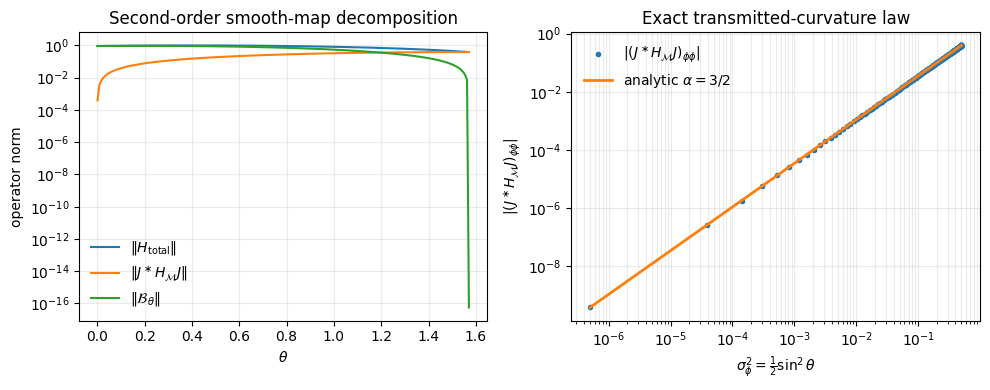

In [32]:
def plot_validation_V_hessian(
    df: pd.DataFrame,
    filename: str = "fig_validationV_hessian_appendix.pdf",
):
    fig, axes = plt.subplots(1, 2, figsize=(10.0, 4.0))

    ax = axes[0]
    ax.plot(df["theta"], df["norm_total"], label=r"$\|H_{\rm total}\|$")
    ax.plot(
        df["theta"],
        df["norm_transmitted"],
        label=r"$\|J^\ast H_{\mathcal{M}}J\|$",
    )
    ax.plot(
        df["theta"],
        df["norm_map_term"],
        label=r"$\|\mathcal{B}_\theta\|$",
    )
    ax.set_xlabel(r"$\theta$")
    ax.set_ylabel("operator norm")
    ax.set_yscale("log")
    ax.grid(True, which="both", alpha=0.25)
    ax.legend(frameon=False)
    ax.set_title("Second-order smooth-map decomposition")

    ax = axes[1]
    ax.plot(
        df["sigma_phi2"],
        np.abs(df["intrinsic_phiphi"]),
        marker=".",
        linestyle="none",
        label=r"$|(J^\ast H_{\mathcal{M}}J)_{\phi\phi}|$",
    )
    ax.plot(
        df["sigma_phi2"],
        df["analytic_abs_intrinsic_phiphi"],
        linewidth=2.0,
        label=r"analytic $\alpha=3/2$",
    )
    ax.set_xlabel(r"$\sigma_\phi^2=\frac{1}{2}\sin^2\theta$")
    ax.set_ylabel(r"$|(J^\ast H_{\mathcal{M}}J)_{\phi\phi}|$")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.grid(True, which="both", alpha=0.25)
    ax.legend(frameon=False)
    ax.set_title("Exact transmitted-curvature law")

    fig.tight_layout()

    path = os.path.join(FIG_DIR, filename)
    fig.savefig(path, bbox_inches="tight")
    fig.savefig(path.replace(".pdf", ".png"), dpi=300, bbox_inches="tight")

    return path


plot_validation_V_hessian(valV_df)


Second-order exact transmission law
Analytic exponent alpha = 3/2
Numerical log-log slope = 1.500000000000
max |numeric - analytic| = 5.551e-17
Pearson r = 1.000000, p = 0.00e+00
Spearman rho = 1.000000, p = 0.00e+00


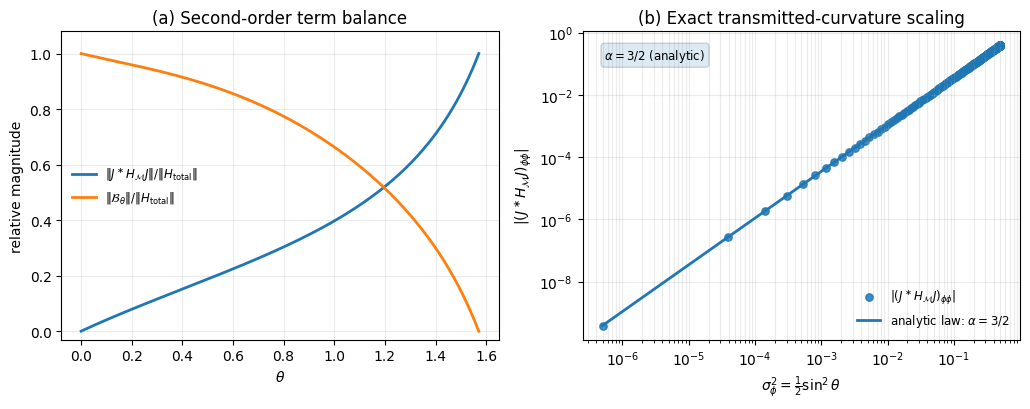

Saved:
figures_jacobian_qfim\fig_validationV_second_order_suppression.pdf


In [33]:
# ==========================================================
# Validation V — paper-ready second-order smooth-map analysis
# ==========================================================

from scipy.stats import pearsonr, spearmanr
import numpy as np
import matplotlib.pyplot as plt
import os


def plot_validation_V_second_order_suppression(
    df: pd.DataFrame,
    filename: str = "fig_validationV_second_order_suppression.pdf",
):
    eps = 1e-18

    theta = df["theta"].to_numpy(dtype=float)

    total = np.maximum(df["norm_total"].to_numpy(dtype=float), eps)
    transmitted = np.maximum(df["norm_transmitted"].to_numpy(dtype=float), eps)
    map_term = np.maximum(df["norm_map_term"].to_numpy(dtype=float), eps)

    sigma2 = df["sigma_phi2"].to_numpy(dtype=float)
    curv_phi = np.abs(df["intrinsic_phiphi"].to_numpy(dtype=float))
    analytic = df["analytic_abs_intrinsic_phiphi"].to_numpy(dtype=float)

    # Numerical log-log fit retained only as a consistency check.
    # The exponent shown in the paper is derived analytically, not inferred from this fit.
    mask = (
        np.isfinite(sigma2)
        & np.isfinite(curv_phi)
        & (sigma2 > 1e-12)
        & (curv_phi > 1e-14)
    )

    logx = np.log10(sigma2[mask])
    logy = np.log10(curv_phi[mask])

    alpha_num, beta_num = np.polyfit(logx, logy, 1)
    r, p = pearsonr(logx, logy)
    rho, ps = spearmanr(logx, logy)

    analytic_error = np.max(np.abs(curv_phi - analytic))

    ratio_transmitted = transmitted / total
    ratio_map = map_term / total

    print("Second-order exact transmission law")
    print("Analytic exponent alpha = 3/2")
    print(f"Numerical log-log slope = {alpha_num:.12f}")
    print(f"max |numeric - analytic| = {analytic_error:.3e}")
    print(f"Pearson r = {r:.6f}, p = {p:.2e}")
    print(f"Spearman rho = {rho:.6f}, p = {ps:.2e}")

    assert abs(alpha_num - 1.5) < 1e-10
    assert analytic_error < 1e-12

    fig, axes = plt.subplots(1, 2, figsize=(10.4, 4.2))

    # ------------------------------------------------------
    # Panel A: relative magnitudes of the Hessian terms
    # ------------------------------------------------------
    ax = axes[0]

    ax.plot(
        theta,
        ratio_transmitted,
        linewidth=2.0,
        label=r"$\|J^\ast H_{\mathcal{M}}J\|/\|H_{\rm total}\|$",
    )

    ax.plot(
        theta,
        ratio_map,
        linewidth=2.0,
        label=r"$\|\mathcal{B}_\theta\|/\|H_{\rm total}\|$",
    )

    ax.set_xlabel(r"$\theta$")
    ax.set_ylabel("relative magnitude")
    ax.set_ylim(-0.03, 1.08)
    ax.set_title("(a) Second-order term balance")
    ax.grid(True, alpha=0.25)
    ax.legend(frameon=False, fontsize=8.5)

    # ------------------------------------------------------
    # Panel B: exact transmitted-curvature law
    # ------------------------------------------------------
    ax = axes[1]

    ax.scatter(
        sigma2[mask],
        curv_phi[mask],
        s=28,
        alpha=0.85,
        label=r"$|(J^\ast H_{\mathcal{M}}J)_{\phi\phi}|$",
    )

    ax.plot(
        sigma2[mask],
        analytic[mask],
        "-",
        linewidth=2.0,
        label=r"analytic law: $\alpha=3/2$",
    )

    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(r"$\sigma_\phi^2=\frac{1}{2}\sin^2\theta$")
    ax.set_ylabel(r"$|(J^\ast H_{\mathcal{M}}J)_{\phi\phi}|$")
    ax.set_title("(b) Exact transmitted-curvature scaling")
    ax.grid(True, which="both", alpha=0.25)
    ax.legend(frameon=False, fontsize=8.5)

    ax.text(
        0.05,
        0.95,
        r"$\alpha=3/2$ (analytic)",
        transform=ax.transAxes,
        va="top",
        ha="left",
        fontsize=8.5,
        bbox=dict(boxstyle="round", alpha=0.15),
    )

    fig.tight_layout()

    path = os.path.join(FIG_DIR, filename)

    fig.savefig(path, bbox_inches="tight")
    fig.savefig(path.replace(".pdf", ".png"), dpi=300, bbox_inches="tight")

    plt.show()

    return path


path_valV_second_order = plot_validation_V_second_order_suppression(valV_df)

print("Saved:")
print(path_valV_second_order)


# Export all generated figures and data

This cell saves dataframes as CSV files and lists all figures. For production, rerun previous cells with larger `n_samples`, wider `ns`, and more depths.

In [34]:
DATA_DIR = "data_jacobian_qfim"
os.makedirs(DATA_DIR, exist_ok=True)

for name, df in [
    ("validation0_modal_identity", val0_df),
    ("validationI_suppression", valI_df),
    ("validationII_scaling", valII_df),
    ("validationII_permutations", perm_df),
    ("validationIII_scaling", valIII_df),
    ("validationIV_predictive", valIV_df),
    ("validationV_hessian", valV_df),
]:
    df.to_csv(os.path.join(DATA_DIR, f"{name}.csv"), index=False)

# Basis-invariant, mode-resolved exports.
def export_mode_blocks(df, prefix, id_col, block_prefix=""):
    rows=[]
    sig_col=block_prefix+"block_sigma2"; a_col=block_prefix+"block_task_coeff"; c_col=block_prefix+"block_modal_contrib"; m_col=block_prefix+"block_multiplicity"
    if sig_col not in df.columns: return
    for _,r in df.iterrows():
        for b,(sig,a,c,m) in enumerate(zip(r[sig_col],r[a_col],r[c_col],r[m_col])):
            rows.append({id_col:r[id_col],"block":b,"sigma2":sig,"task_coeff_block":a,"modal_contrib_block":c,"multiplicity":m})
    pd.DataFrame(rows).to_csv(os.path.join(DATA_DIR,f"{prefix}_mode_blocks.csv"),index=False)
export_mode_blocks(perm_df,"validationII_permutations","perm")
export_mode_blocks(valIV_df,"validationIV_predictive","instance",block_prefix="init_")

print("Figures:")
for f in sorted(os.listdir(FIG_DIR)):
    print(" -", os.path.join(FIG_DIR, f))

print("\nData:")
for f in sorted(os.listdir(DATA_DIR)):
    print(" -", os.path.join(DATA_DIR, f))


# Robustness-control outputs are written incrementally by the long-running cell.
if os.path.isdir("robustness_controls"):
    print("\nRobustness controls:")
    for f in sorted(os.listdir("robustness_controls")):
        print(" -", os.path.join("robustness_controls", f))


Figures:
 - figures_jacobian_qfim/fig_validation0_modal_identity.pdf
 - figures_jacobian_qfim/fig_validationIII_scaling_local_global.pdf
 - figures_jacobian_qfim/fig_validationIII_scaling_local_global.png
 - figures_jacobian_qfim/fig_validationII_dla_same_jacobian_different.pdf
 - figures_jacobian_qfim/fig_validationII_dla_same_jacobian_different.png
 - figures_jacobian_qfim/fig_validationII_jacobian_geometry_permutations.pdf
 - figures_jacobian_qfim/fig_validationII_jacobian_geometry_permutations.png
 - figures_jacobian_qfim/fig_validationII_permutation_distribution.pdf
 - figures_jacobian_qfim/fig_validationIV_predictive_training.pdf
 - figures_jacobian_qfim/fig_validationIV_predictive_training.png
 - figures_jacobian_qfim/fig_validationIV_predictor_ranking.pdf
 - figures_jacobian_qfim/fig_validationIV_predictor_ranking.png
 - figures_jacobian_qfim/fig_validationI_suppression_mechanisms.pdf
 - figures_jacobian_qfim/fig_validationI_suppression_mechanisms.png
 - figures_jacobian_qfim/f